# LightGBM Classifier

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Light Gradient Boosting Machine (LightGBM) is an efficient gradient boosting framework designed for high-performance machine learning on structured datasets.

This notebook develops a LightGBM classifier using the PCA-transformed applicant dataset to predict loan default.

The objectives are to:

- Train a LightGBM classifier.
- Predict applicant default probabilities.
- Evaluate classification performance.
- Analyze feature importance.
- Compare LightGBM with all previously developed models.

# Import Required Libraries

The following libraries are required for model development, evaluation, and visualization.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed datasets created during feature engineering are loaded for model training and evaluation.

In [2]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Train LightGBM Model

A LightGBM classifier is trained using the PCA-transformed training dataset.

Class imbalance is handled using the `scale_pos_weight` parameter.

In [3]:
# ============================================================
# Train LightGBM
# ============================================================

scale_pos_weight = (
    y_train.value_counts()[0] /
    y_train.value_counts()[1]
)

lgbm_model = LGBMClassifier(

    n_estimators=300,

    learning_rate=0.05,

    max_depth=6,

    subsample=0.8,

    colsample_bytree=0.8,

    scale_pos_weight=scale_pos_weight,

    random_state=42

)

lgbm_model.fit(
    X_train,
    y_train
)

print("LightGBM model trained successfully.")

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.050872 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 30345
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 119
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482


LightGBM model trained successfully.


# Generate Predictions

The trained LightGBM classifier predicts both class labels and the probability of default.

In [4]:
# ============================================================
# Predictions
# ============================================================

y_pred = lgbm_model.predict(X_test)

y_prob = lgbm_model.predict_proba(X_test)[:,1]

# Model Evaluation

The LightGBM classifier is evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

In [5]:
accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(y_test,y_pred)

recall = recall_score(y_test,y_pred)

f1 = f1_score(y_test,y_pred)

auc = roc_auc_score(y_test,y_prob)

metrics = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.720485
1,Precision,0.173555
2,Recall,0.654582
3,F1 Score,0.274366
4,ROC AUC,0.754543


# Confusion Matrix

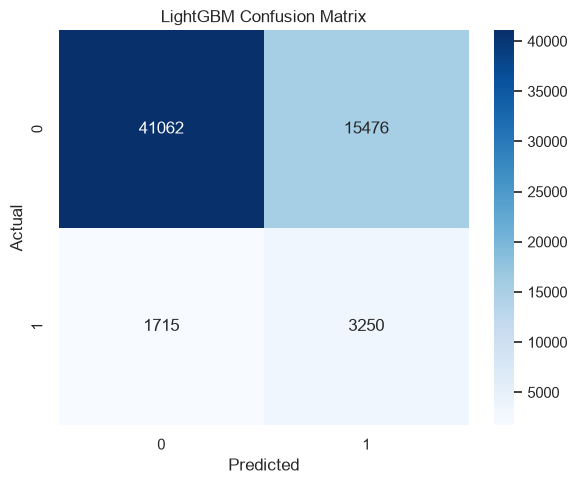

In [6]:
cm = confusion_matrix(y_test,y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("LightGBM Confusion Matrix")

plt.tight_layout()

plt.show()

# Classification Report

In [7]:
print(classification_report(
    y_test,
    y_pred
))

              precision    recall  f1-score   support

           0       0.96      0.73      0.83     56538
           1       0.17      0.65      0.27      4965

    accuracy                           0.72     61503
   macro avg       0.57      0.69      0.55     61503
weighted avg       0.90      0.72      0.78     61503



# ROC Curve

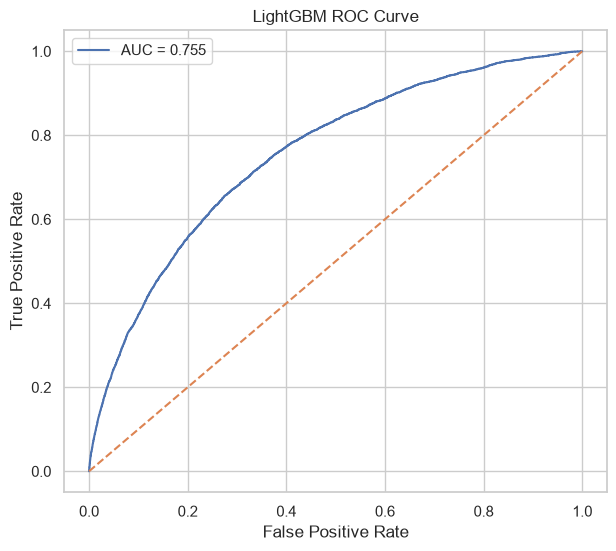

In [8]:
fpr,tpr,_ = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("LightGBM ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# Feature Importance

LightGBM estimates feature importance based on the contribution of each principal component to reducing the training loss.

The most influential principal components are identified below.

In [9]:
feature_importance = (

    pd.DataFrame({

        "Feature":X_train.columns,

        "Importance":lgbm_model.feature_importances_

    })

    .sort_values(
        "Importance",
        ascending=False
    )

)

feature_importance.head(15)

,Feature,Importance
7,PC8,255
19,PC20,231
8,PC9,230
30,PC31,218
28,PC29,211
1,PC2,210
17,PC18,194
107,PC108,186
2,PC3,180
5,PC6,174


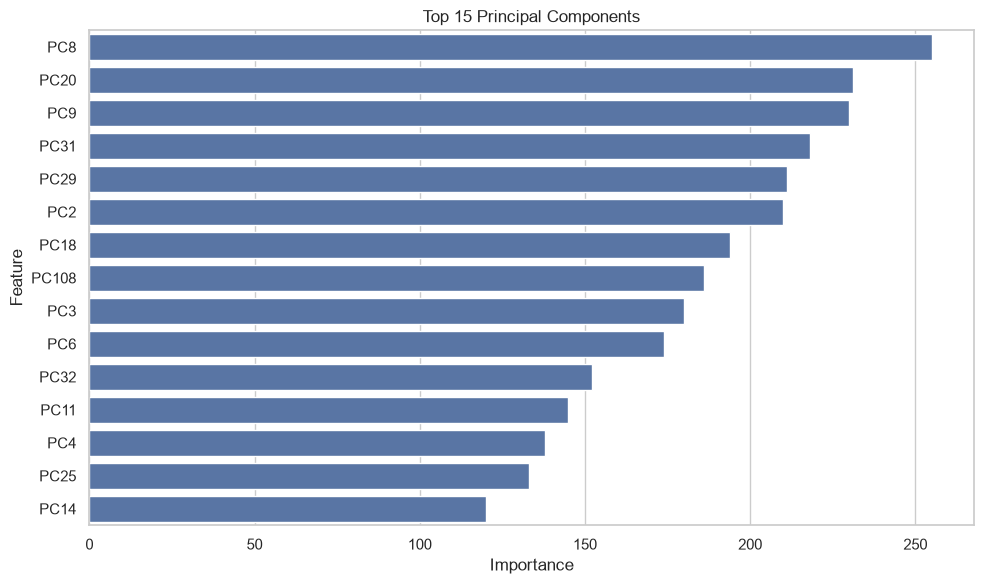

In [10]:
plt.figure(figsize=(10,6))

sns.barplot(

    data=feature_importance.head(15),

    x="Importance",

    y="Feature"

)

plt.title("Top 15 Principal Components")

plt.tight_layout()

plt.show()

# Model Configuration

The LightGBM classifier was trained using:

- Number of Trees = 300
- Learning Rate = 0.05
- Maximum Tree Depth = 6
- Subsample = 0.80
- Column Sample by Tree = 0.80
- Class Weight = Balanced using `scale_pos_weight`

These parameters improve model performance while addressing class imbalance.

# Save Trained Model

The trained Logistic Regression model is saved for future prediction, evaluation, and deployment.

In [11]:
# ============================================================
# Save LightGBM Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    lgbm_model,
    MODEL_DIR / "lightgbm_model.pkl"
)

print("LightGBM model saved successfully.")

LightGBM model saved successfully.


# Save Model Performance

The evaluation metrics of the LightGBM classifier are appended to the common model results file for comparison with all previously developed machine learning models.

In [12]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["LightGBM"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,LightGBM,0.720485,0.173555,0.654582,0.274366,0.754543,15476,1715,3250,41062


# Conclusion

The LightGBM classifier was successfully trained and evaluated using the PCA-transformed applicant dataset.

## Key Outcomes

- A gradient boosting model optimized for large-scale structured datasets was developed.
- Performance was evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- Feature importance analysis identified the principal components contributing most to loan default prediction.
- The confusion matrix and ROC curve demonstrated the model's classification capability.
- Performance metrics were recorded for comparison with all previous machine learning models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 13 – Model Comparison, Credit Risk Score Generation, and Fairness Analysis**

---

# Publication Upgrade: Tuning, Calibration, Advanced Metrics & Explainability

This notebook receives the most detailed explainability treatment in the project:
LightGBM is the fastest of the three tree ensembles to fit and to explain with SHAP,
and — together with XGBoost — is one of the two strongest candidates for the final
production model selected in Notebook 13. Its SHAP results here should be treated as
the project's primary, citable explainability case study.

**Hardware-aware tuning:** as in Notebook 10, the search estimator below uses
`n_jobs=1` while `RandomizedSearchCV` parallelizes across candidates/folds with a
bounded `n_jobs=12` (of 24 available threads on the Intel Core Ultra 9 275HX) —
nesting `n_jobs=-1` inside `n_jobs=-1` oversubscribes the CPU and was the root cause
of a 50+ minute stall in Notebook 10's Random Forest search. LightGBM's histogram-based
algorithm is inherently far more CPU/memory-efficient than scikit-learn's Random
Forest at this row count, so this fix mainly avoids repeating the same mistake rather
than fixing an already-observed stall here.

## 1. Hyperparameter Optimization (RandomizedSearchCV)

Like the XGBoost baseline, this LightGBM baseline already uses `scale_pos_weight` for
imbalance handling, giving it a similarly strong baseline recall (65.5%). The search
below explores tree complexity (`num_leaves`, `max_depth`), learning rate, boosting
rounds, row/column subsampling, and a range of `scale_pos_weight` multipliers using
`RandomizedSearchCV`, structured to match Notebook 11's XGBoost search for a fair,
apples-to-apples comparison between the two boosting frameworks.

In [13]:
# ============================================================
# Hyperparameter Optimization: RandomizedSearchCV (hardware-optimized)
# ============================================================

import sys
sys.path.append(str(Path(".").resolve()))
import pub_utils as pu

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

pu.set_pub_style()

RANDOM_STATE = 42

param_distributions = {
    "n_estimators": [100, 200, 300],
    "num_leaves": [15, 31, 63, 127],
    "max_depth": [-1, 5, 7, 10],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "scale_pos_weight": [scale_pos_weight * f for f in (0.5, 1.0, 1.5, 2.0)],
}

N_ITER = 15
SEARCH_N_JOBS = 12  # bounded below the 24 available threads (see markdown above)

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
total_fits = N_ITER * cv_strategy.get_n_splits()

# n_jobs=1 on the estimator: RandomizedSearchCV already parallelizes across
# candidates/folds, so nesting n_jobs=-1 here would oversubscribe the CPU.
random_search = RandomizedSearchCV(
    estimator=LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=SEARCH_N_JOBS,
    random_state=RANDOM_STATE,
    refit=False,  # refit standalone below with n_jobs=-1 for a faster final fit
    verbose=0,
)

with pu.tqdm_joblib(desc="Tuning LightGBM (RandomizedSearchCV)", total=total_fits):
    random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print(f"Best Cross-Validated ROC-AUC: {random_search.best_score_:.4f}")

# Single standalone refit of the winning configuration with full CPU parallelism.
lgbm_model_tuned = LGBMClassifier(
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, **random_search.best_params_
)
lgbm_model_tuned.fit(X_train, y_train)

cv_results_summary = (
    pd.DataFrame(random_search.cv_results_)[
        ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    ]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

cv_results_summary.head(10)

Tuning LightGBM (RandomizedSearchCV):   0%|          | 0/45 [00:00<?, ?it/s]

Best Parameters: {'subsample': 1.0, 'scale_pos_weight': np.float64(11.38710976837865), 'num_leaves': 15, 'n_estimators': 300, 'max_depth': 10, 'learning_rate': 0.05, 'colsample_bytree': 0.6}
Best Cross-Validated ROC-AUC: 0.7508


,params,mean_test_score,std_test_score,rank_test_score
0,"{'subsample': 1.0, 'scale_pos_weight': 11.3871...",0.750761,0.000452,1
1,"{'subsample': 0.8, 'scale_pos_weight': 22.7742...",0.750158,0.000893,2
2,"{'subsample': 0.8, 'scale_pos_weight': 22.7742...",0.748361,0.000530,3
3,"{'subsample': 1.0, 'scale_pos_weight': 17.0806...",0.747910,0.000180,4
4,"{'subsample': 0.8, 'scale_pos_weight': 5.69355...",0.746826,0.000784,5
5,"{'subsample': 0.8, 'scale_pos_weight': 5.69355...",0.745087,0.001043,6
6,"{'subsample': 0.8, 'scale_pos_weight': 5.69355...",0.741280,0.000798,7
7,"{'subsample': 0.8, 'scale_pos_weight': 17.0806...",0.740566,0.001438,8
8,"{'subsample': 0.8, 'scale_pos_weight': 22.7742...",0.734939,0.000548,9
9,"{'subsample': 1.0, 'scale_pos_weight': 5.69355...",0.732764,0.001613,10


Figure saved to: ..\figures\12_lgbm_baseline_vs_tuned.png


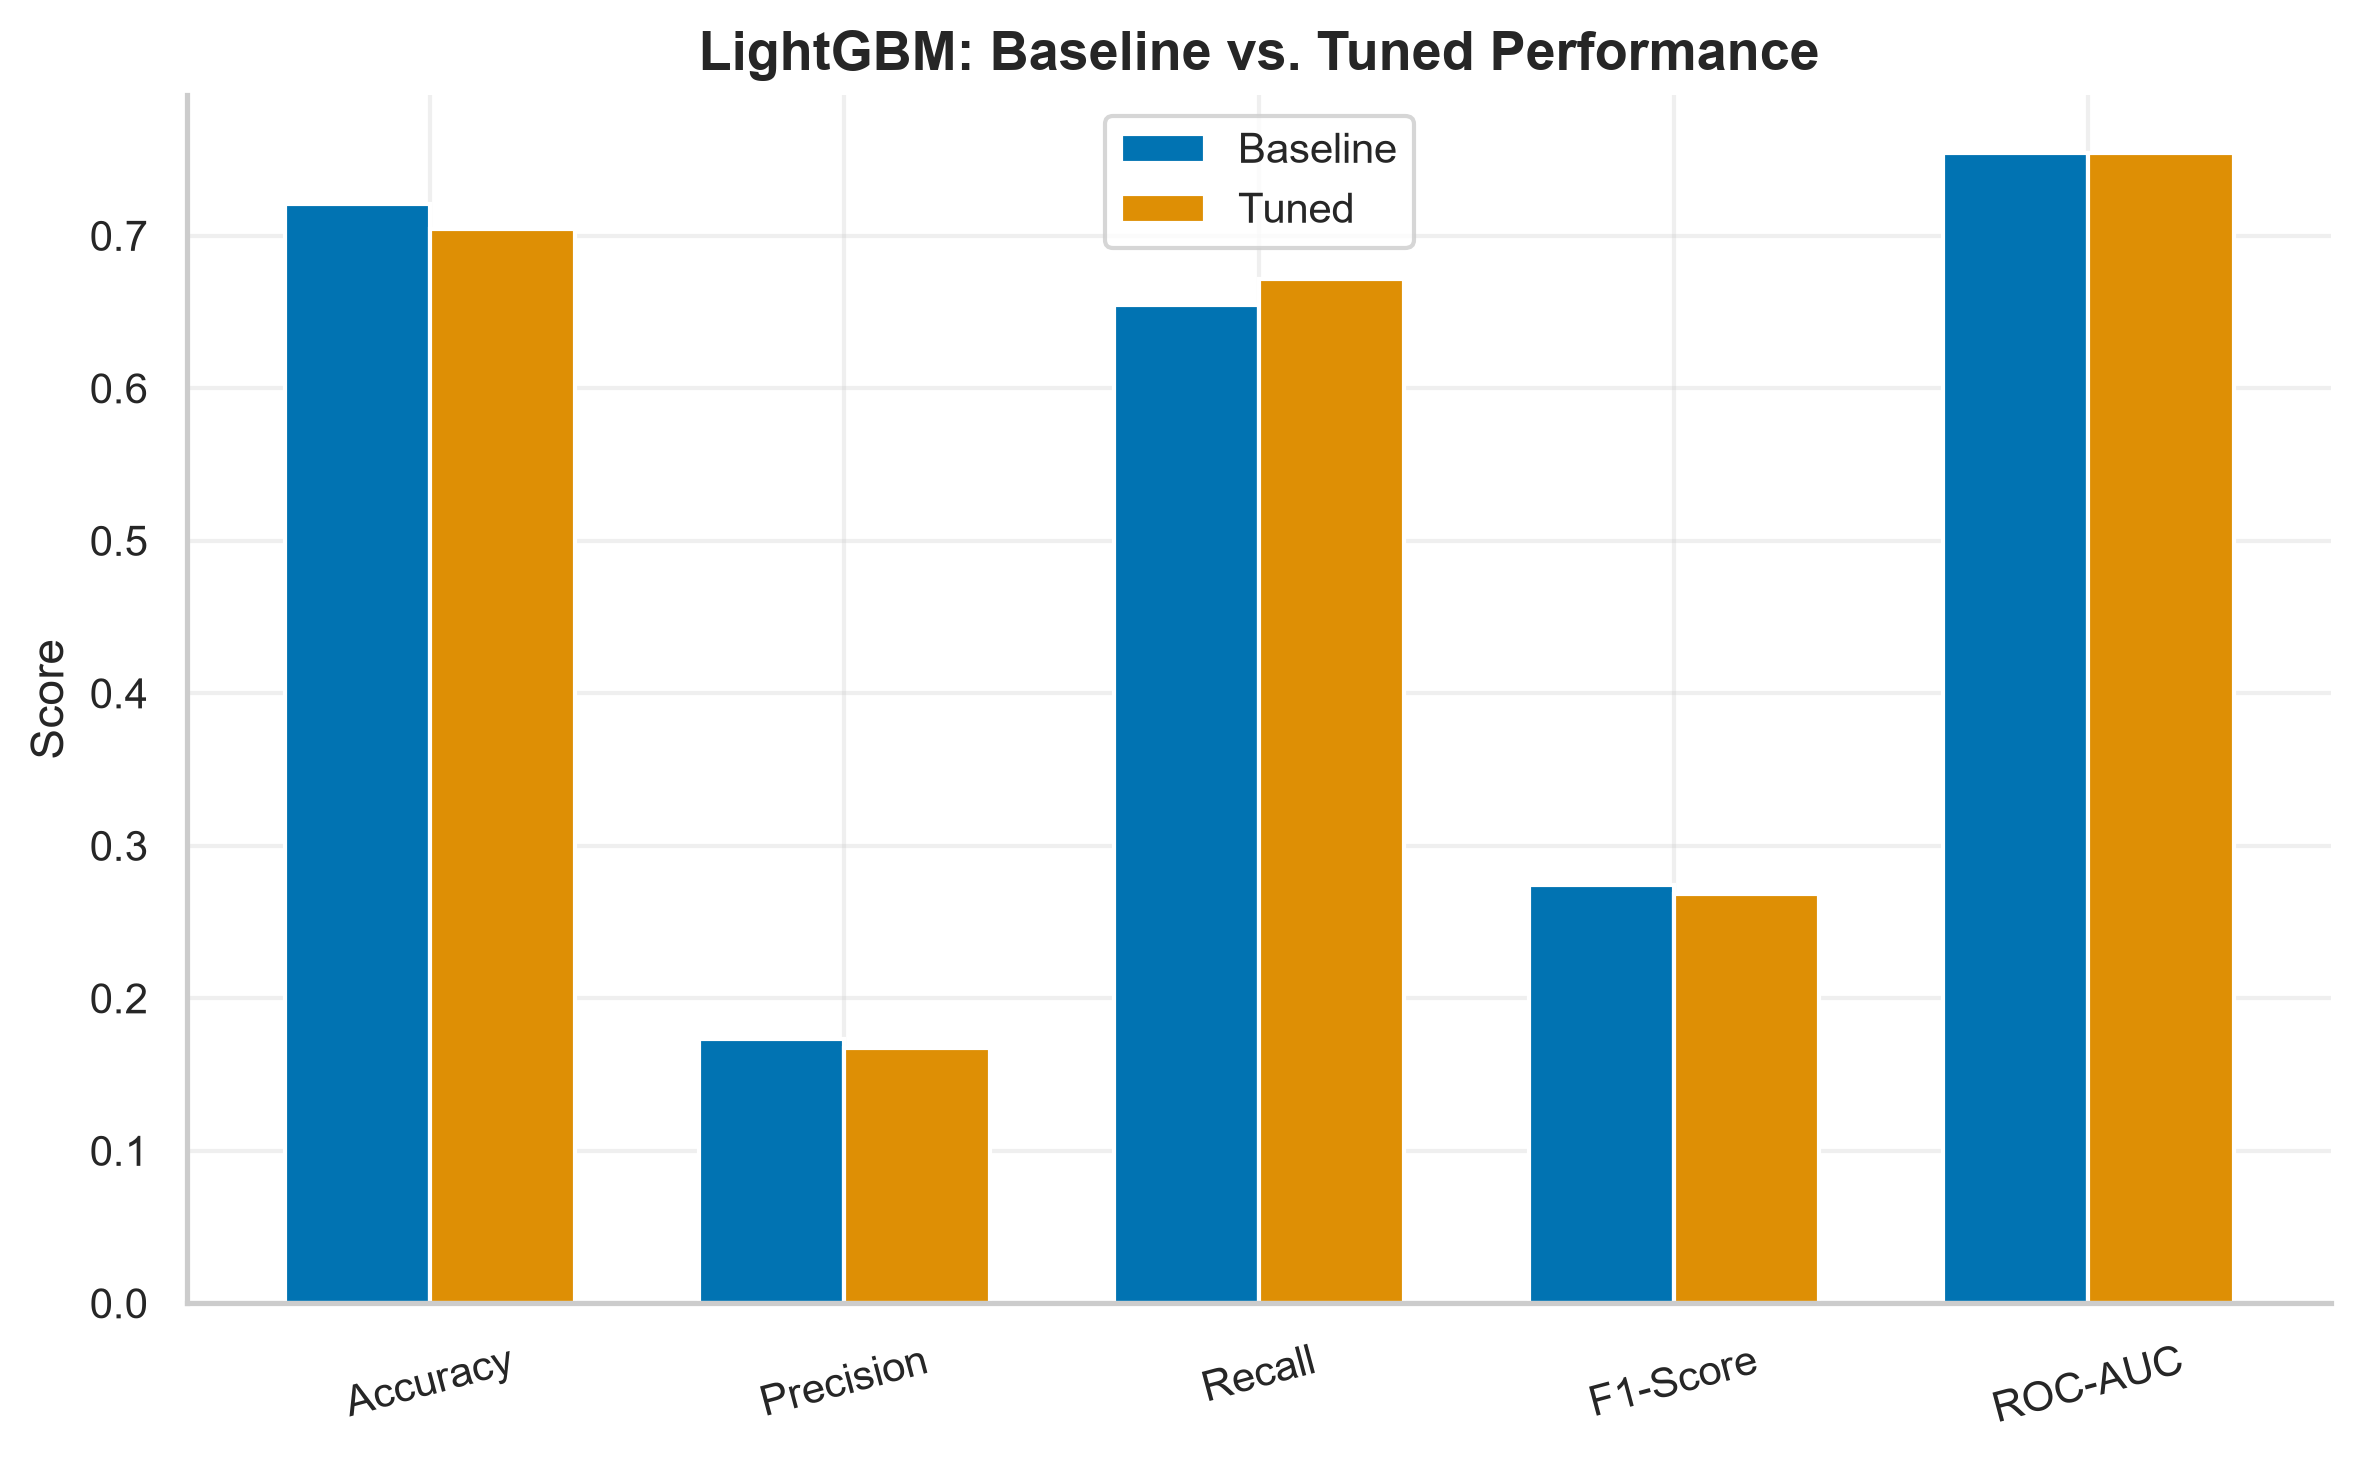

,Metric,Baseline,Tuned,Improvement,Improvement (%)
0,Accuracy,0.720485,0.704226,-0.016259,-2.26
1,Precision,0.173555,0.167655,-0.005900,-3.40
2,Recall,0.654582,0.671903,0.017321,2.65
3,F1-Score,0.274366,0.268351,-0.006015,-2.19
4,ROC-AUC,0.754543,0.754001,-0.000542,-0.07


In [14]:
# ============================================================
# Baseline vs. Tuned Model Comparison
# ============================================================

y_pred_tuned = lgbm_model_tuned.predict(X_test)
y_prob_tuned = lgbm_model_tuned.predict_proba(X_test)[:, 1]

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_prob_tuned)
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

comparison_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Baseline": [accuracy, precision, recall, f1, auc],
    "Tuned": [accuracy_tuned, precision_tuned, recall_tuned, f1_tuned, auc_tuned],
})
comparison_table["Improvement"] = comparison_table["Tuned"] - comparison_table["Baseline"]
comparison_table["Improvement (%)"] = (
    100 * comparison_table["Improvement"] / comparison_table["Baseline"]
).round(2)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(comparison_table))
width = 0.35
ax.bar(x - width / 2, comparison_table["Baseline"], width, label="Baseline")
ax.bar(x + width / 2, comparison_table["Tuned"], width, label="Tuned")
ax.set_xticks(x)
ax.set_xticklabels(comparison_table["Metric"], rotation=15)
ax.set_ylabel("Score")
ax.set_title("LightGBM: Baseline vs. Tuned Performance")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "12_lgbm_baseline_vs_tuned")
plt.show()

joblib.dump(lgbm_model_tuned, MODEL_DIR / "lightgbm_tuned_model.pkl")

tuned_result = pd.DataFrame({
    "Model": ["LightGBM (Tuned)"],
    "Accuracy": [accuracy_tuned],
    "Precision": [precision_tuned],
    "Recall": [recall_tuned],
    "F1 Score": [f1_tuned],
    "ROC AUC": [auc_tuned],
    "False Positives": [cm_tuned[0, 1]],
    "False Negatives": [cm_tuned[1, 0]],
    "True Positives": [cm_tuned[1, 1]],
    "True Negatives": [cm_tuned[0, 0]],
})
pu.append_csv(OUTPUT_DIR / "model_results.csv", tuned_result)

comparison_table

### Business Interpretation: Hyperparameter Optimization

`num_leaves` is LightGBM's most influential complexity control (it grows leaf-wise
rather than XGBoost's level-wise strategy, so it can reach higher effective complexity
per tree). If the search favors a moderate `num_leaves` (31-63) over the extremes, that
suggests the baseline's complexity was already close to appropriate for this dataset;
a large jump toward 127 leaves alongside a meaningfully higher CV ROC-AUC would instead
suggest the baseline was underfitting relative to what the ~250K-row training set can
support. Compare the tuned `scale_pos_weight` chosen here against Notebook 11's XGBoost
result: if both boosting frameworks converge on a similar imbalance-correction factor,
that is strong cross-framework evidence for what the "right" cost trade-off for this
portfolio actually is, independent of implementation details.

## 2. Probability Calibration

Figure saved to: ..\figures\12_lgbm_calibration_curve.png


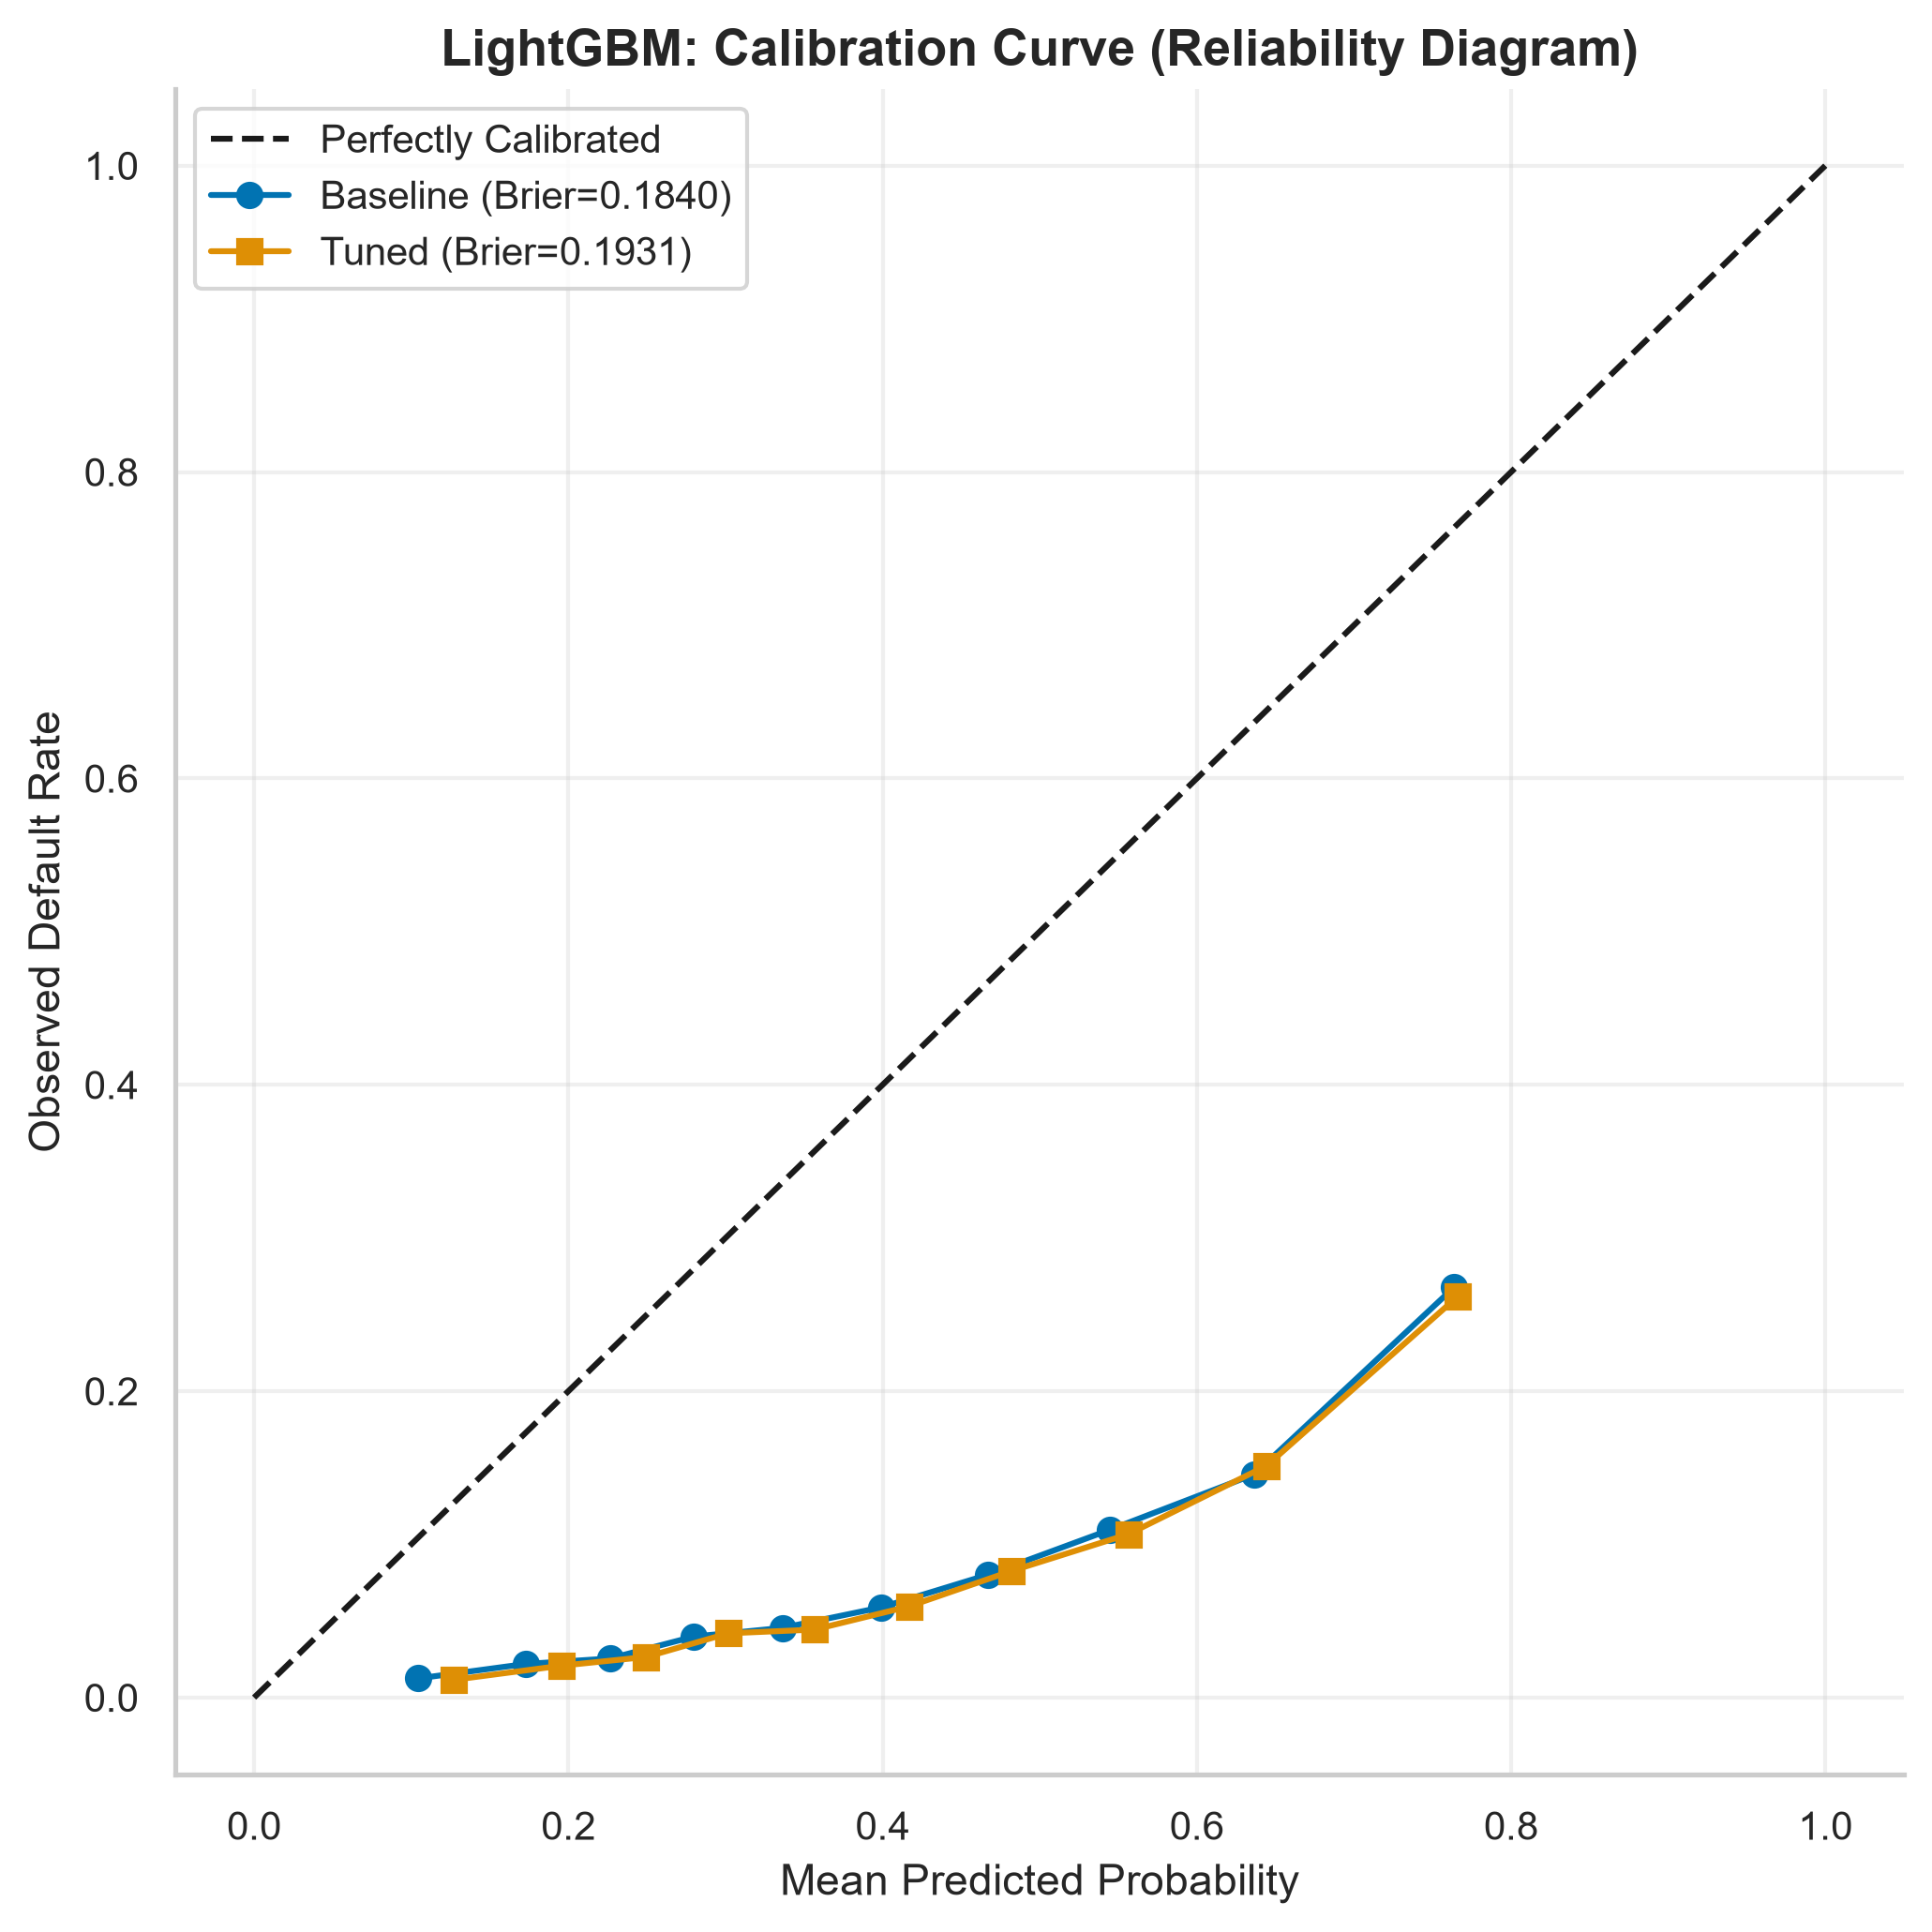

Brier Score - Baseline : 0.1840
Brier Score - Tuned    : 0.1931  (lower is better; 0 = perfect)


Fitting calibrated variants:   0%|          | 0/2 [00:00<?, ?it/s]

Brier Score - Sigmoid   : 0.0681


Brier Score - Isotonic  : 0.0681

Best calibration approach: isotonic (Brier = 0.0681)
Best-calibrated model saved to: ../models/lightgbm_calibrated_model.pkl


,Brier Score
tuned_uncalibrated,0.193084
sigmoid,0.068150
isotonic,0.068137


In [15]:
# ============================================================
# Calibration Curve, Brier Score & CalibratedClassifierCV
# ============================================================

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss
from tqdm.auto import tqdm

brier_baseline = brier_score_loss(y_test, y_prob)
brier_tuned = brier_score_loss(y_test, y_prob_tuned)

frac_pos_baseline, mean_pred_baseline = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")
frac_pos_tuned, mean_pred_tuned = calibration_curve(y_test, y_prob_tuned, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], "k--", label="Perfectly Calibrated")
ax.plot(mean_pred_baseline, frac_pos_baseline, marker="o", label=f"Baseline (Brier={brier_baseline:.4f})")
ax.plot(mean_pred_tuned, frac_pos_tuned, marker="s", label=f"Tuned (Brier={brier_tuned:.4f})")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Default Rate")
ax.set_title("LightGBM: Calibration Curve (Reliability Diagram)")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "12_lgbm_calibration_curve")
plt.show()

print(f"Brier Score - Baseline : {brier_baseline:.4f}")
print(f"Brier Score - Tuned    : {brier_tuned:.4f}  (lower is better; 0 = perfect)")

# CalibratedClassifierCV does not parallelize its own folds by default, so n_jobs=-1
# on the inner estimator is safe here (no nesting issue). cv=3 (not 5) for speed.
calibration_results = {"tuned_uncalibrated": brier_tuned}
calibrated_models = {}

for method in tqdm(["sigmoid", "isotonic"], desc="Fitting calibrated variants"):
    calibrated = CalibratedClassifierCV(
        estimator=LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, **random_search.best_params_),
        method=method,
        cv=3,
    )
    calibrated.fit(X_train, y_train)
    prob_calibrated = calibrated.predict_proba(X_test)[:, 1]
    brier = brier_score_loss(y_test, prob_calibrated)
    calibration_results[method] = brier
    calibrated_models[method] = calibrated
    print(f"Brier Score - {method.capitalize():<10}: {brier:.4f}")

best_method = min(calibration_results, key=calibration_results.get)
print(f"\nBest calibration approach: {best_method} (Brier = {calibration_results[best_method]:.4f})")

if best_method in calibrated_models:
    joblib.dump(calibrated_models[best_method], MODEL_DIR / "lightgbm_calibrated_model.pkl")
    print("Best-calibrated model saved to: ../models/lightgbm_calibrated_model.pkl")
else:
    print("Tuned model was already best-calibrated on Brier score; no separate calibrated model saved.")

pd.Series(calibration_results, name="Brier Score").to_frame()

### Business Interpretation: Probability Calibration

As LightGBM's closest peer in this project (XGBoost) is also a strong production
candidate, comparing the two models' Brier scores side by side (this notebook vs.
Notebook 11) is itself a useful tie-breaker input for Notebook 13's model selection —
if the two have statistically indistinguishable ROC-AUC (formally tested with DeLong's
test in Notebook 13) but LightGBM has a meaningfully lower Brier score, that is a
legitimate reason to prefer LightGBM for the production scoring model even without a
discrimination advantage, since the credit score itself is a direct function of
calibrated probability quality, not ranking quality.

## 3. Additional Evaluation Metrics

Figure saved to: ..\figures\12_lgbm_precision_recall_curve.png


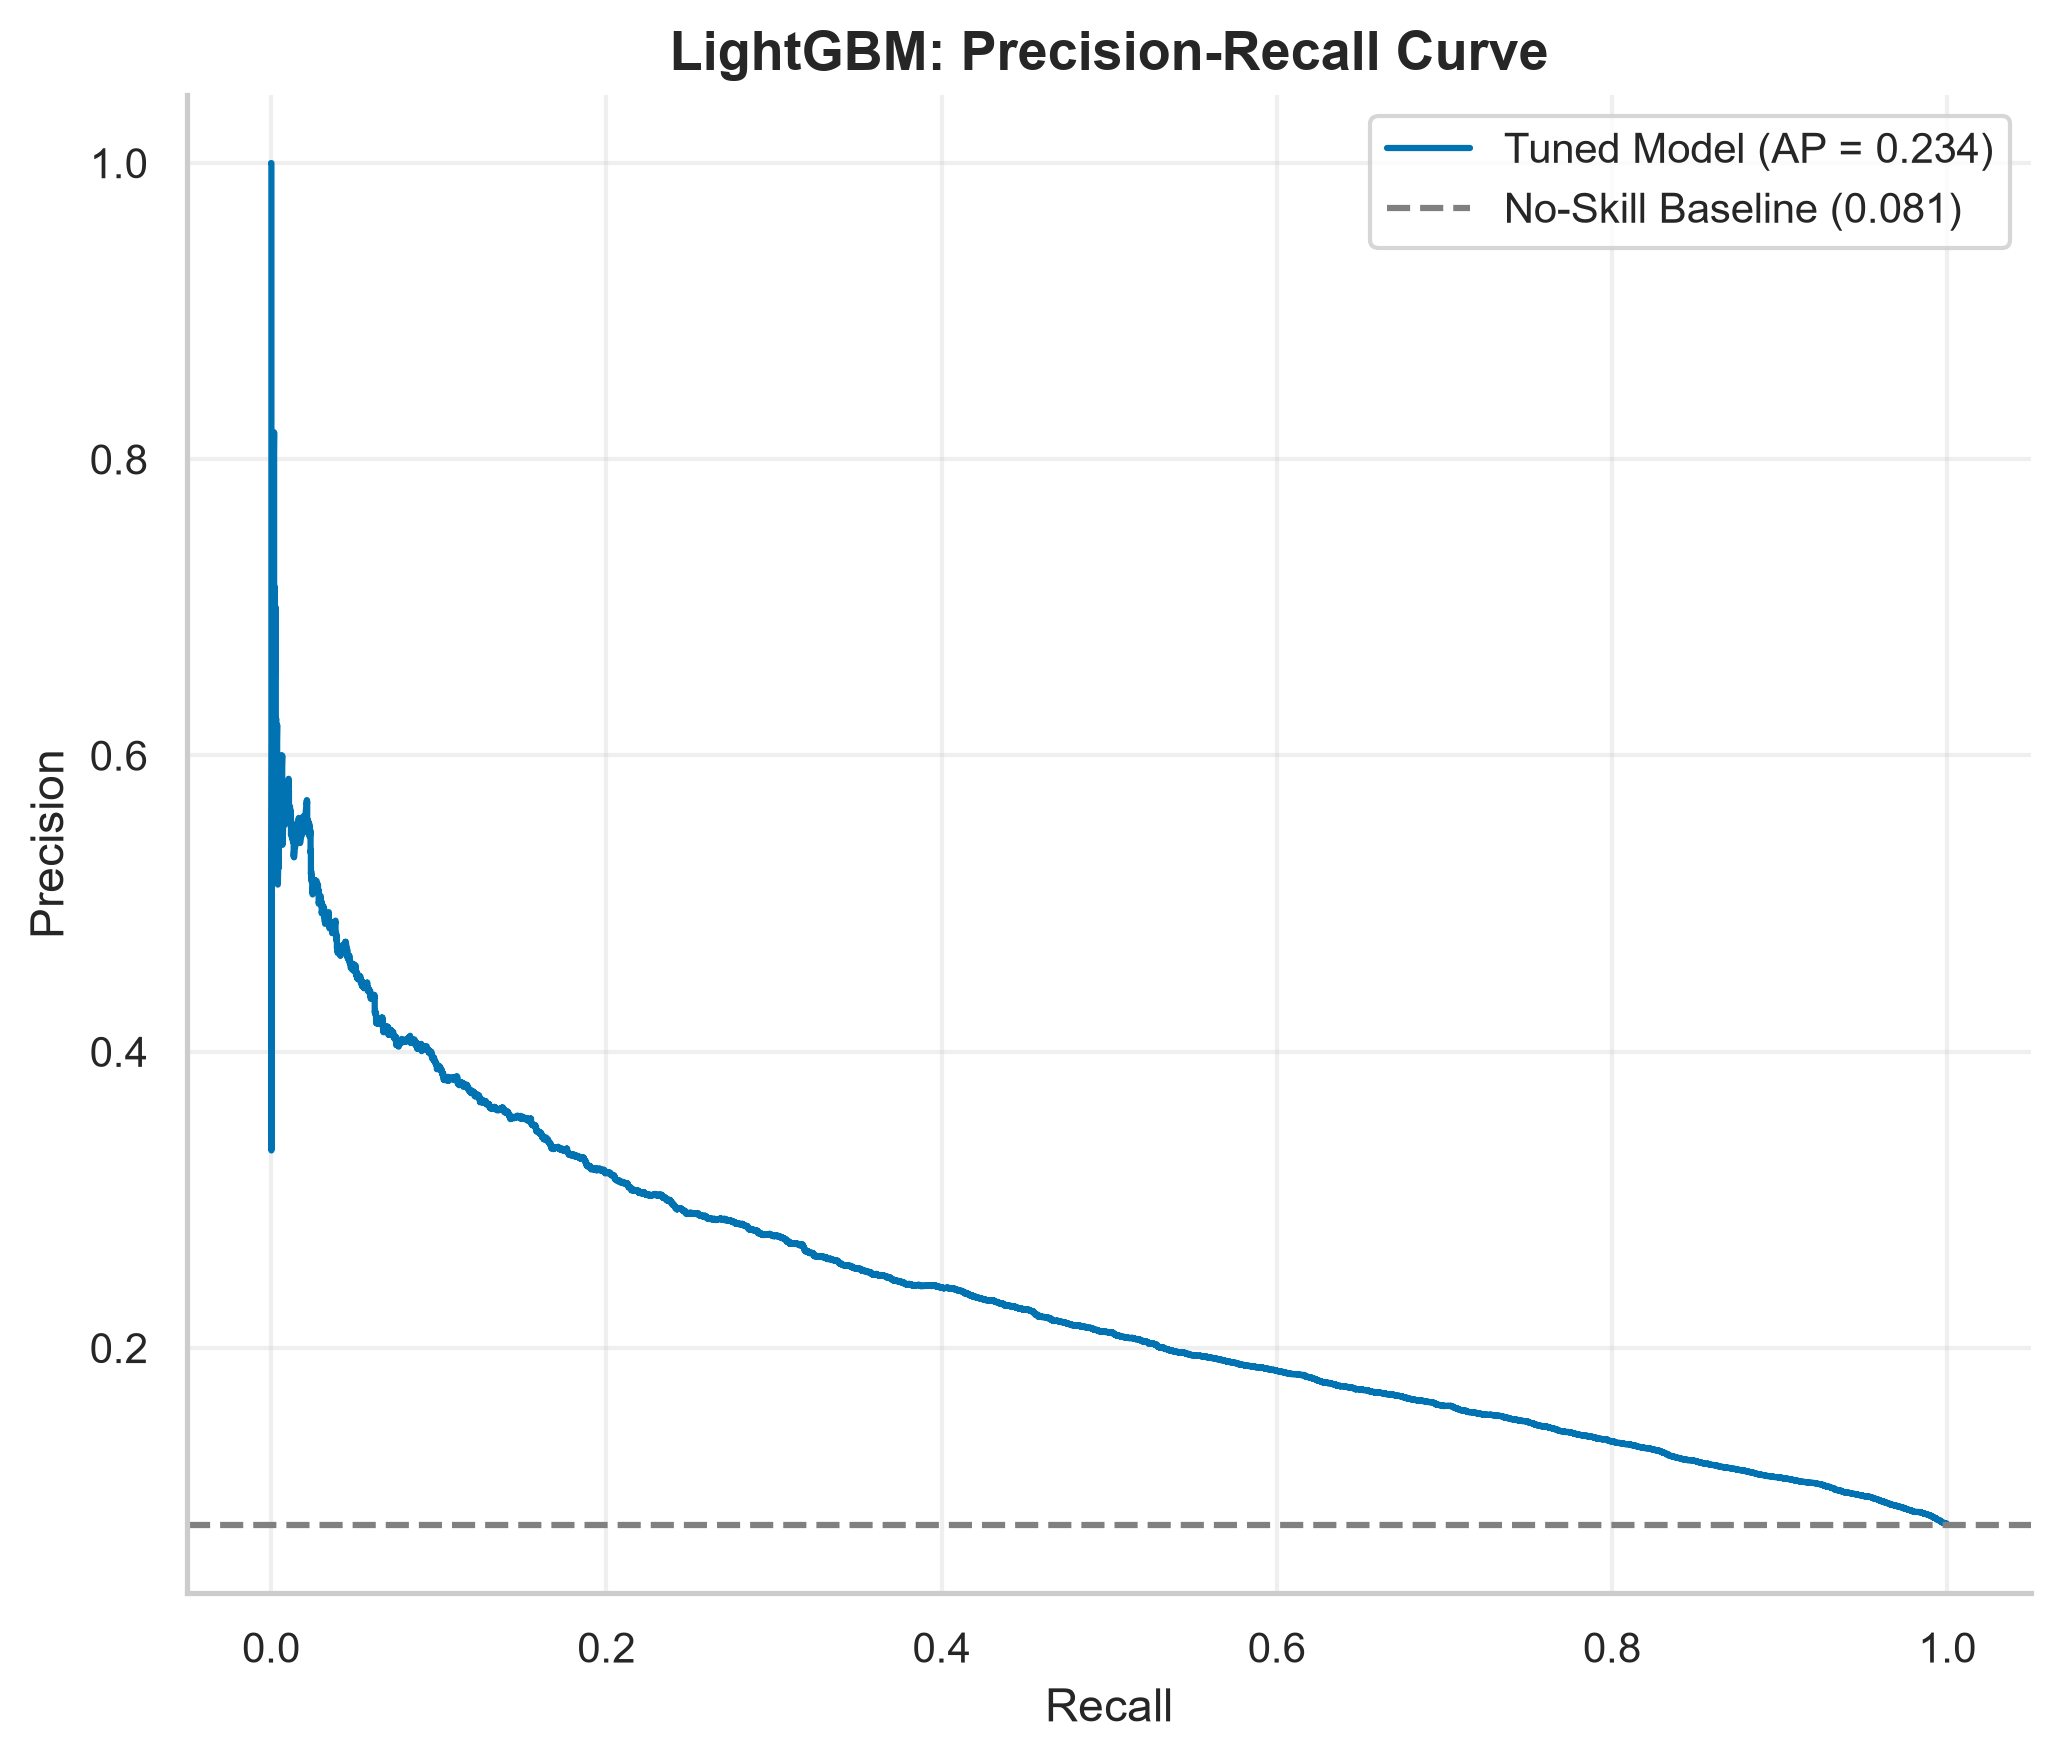

,Model,Variant,Accuracy,Precision,Recall,F1 Score,ROC AUC,MCC,Cohen's Kappa,Average Precision (PR-AUC),KS Statistic,Brier Score
0,LightGBM,Baseline,0.720485,0.173555,0.654582,0.274366,0.754543,0.225456,0.168214,0.234525,0.380964,0.184023
1,LightGBM,Tuned,0.704226,0.167655,0.671903,0.268351,0.754001,0.220676,0.159783,0.234068,0.381641,0.193084


In [16]:
# ============================================================
# Additional Evaluation Metrics: MCC, Kappa, PR-AUC, KS Statistic
# ============================================================

from sklearn.metrics import (
    matthews_corrcoef,
    cohen_kappa_score,
    precision_recall_curve,
    average_precision_score,
)

def extra_metrics(y_true, y_pred, y_prob):
    return {
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "Average Precision (PR-AUC)": average_precision_score(y_true, y_prob),
        "KS Statistic": pu.ks_statistic(y_true, y_prob),
        "Brier Score": brier_score_loss(y_true, y_prob),
    }

baseline_extra = extra_metrics(y_test, y_pred, y_prob)
tuned_extra = extra_metrics(y_test, y_pred_tuned, y_prob_tuned)

extended_row = pd.DataFrame([
    {"Model": "LightGBM", "Variant": "Baseline",
     "Accuracy": accuracy, "Precision": precision, "Recall": recall,
     "F1 Score": f1, "ROC AUC": auc, **baseline_extra},
    {"Model": "LightGBM", "Variant": "Tuned",
     "Accuracy": accuracy_tuned, "Precision": precision_tuned, "Recall": recall_tuned,
     "F1 Score": f1_tuned, "ROC AUC": auc_tuned, **tuned_extra},
])

pu.append_csv(OUTPUT_DIR / "model_results_extended.csv", extended_row)

precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob_tuned)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(recall_curve, precision_curve,
        label=f"Tuned Model (AP = {tuned_extra['Average Precision (PR-AUC)']:.3f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label=f"No-Skill Baseline ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("LightGBM: Precision-Recall Curve")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "12_lgbm_precision_recall_curve")
plt.show()

extended_row

### Business Interpretation: Additional Metrics

LightGBM's MCC, Kappa, and KS statistic should be closely tracking XGBoost's
(Notebook 11) given their similar baseline design — any material gap between the two
here, after tuning, is the strongest single piece of quantitative evidence for Notebook
13's final model choice between them, more informative than ROC-AUC alone since these
metrics are explicitly sensitive to the class imbalance both models are trying to
address.

## 4. SHAP Explainability (Flagship Analysis)

LightGBM's `TreeExplainer` is the fastest of the three tree-based explainers used in
this project, making it practical to explain a larger sample and to go one step further
than Notebooks 07/10/11: beyond the standard summary plot, feature importance,
dependence plot, and two local explanations, this section adds a **multi-applicant
decision plot** spanning the full risk spectrum (not just the single lowest/highest-risk
applicant), giving the clearest picture in the project of how predicted risk actually
accumulates feature-by-feature across a representative population of applicants.

Figure saved to: ..\figures\12_lgbm_shap_summary.png


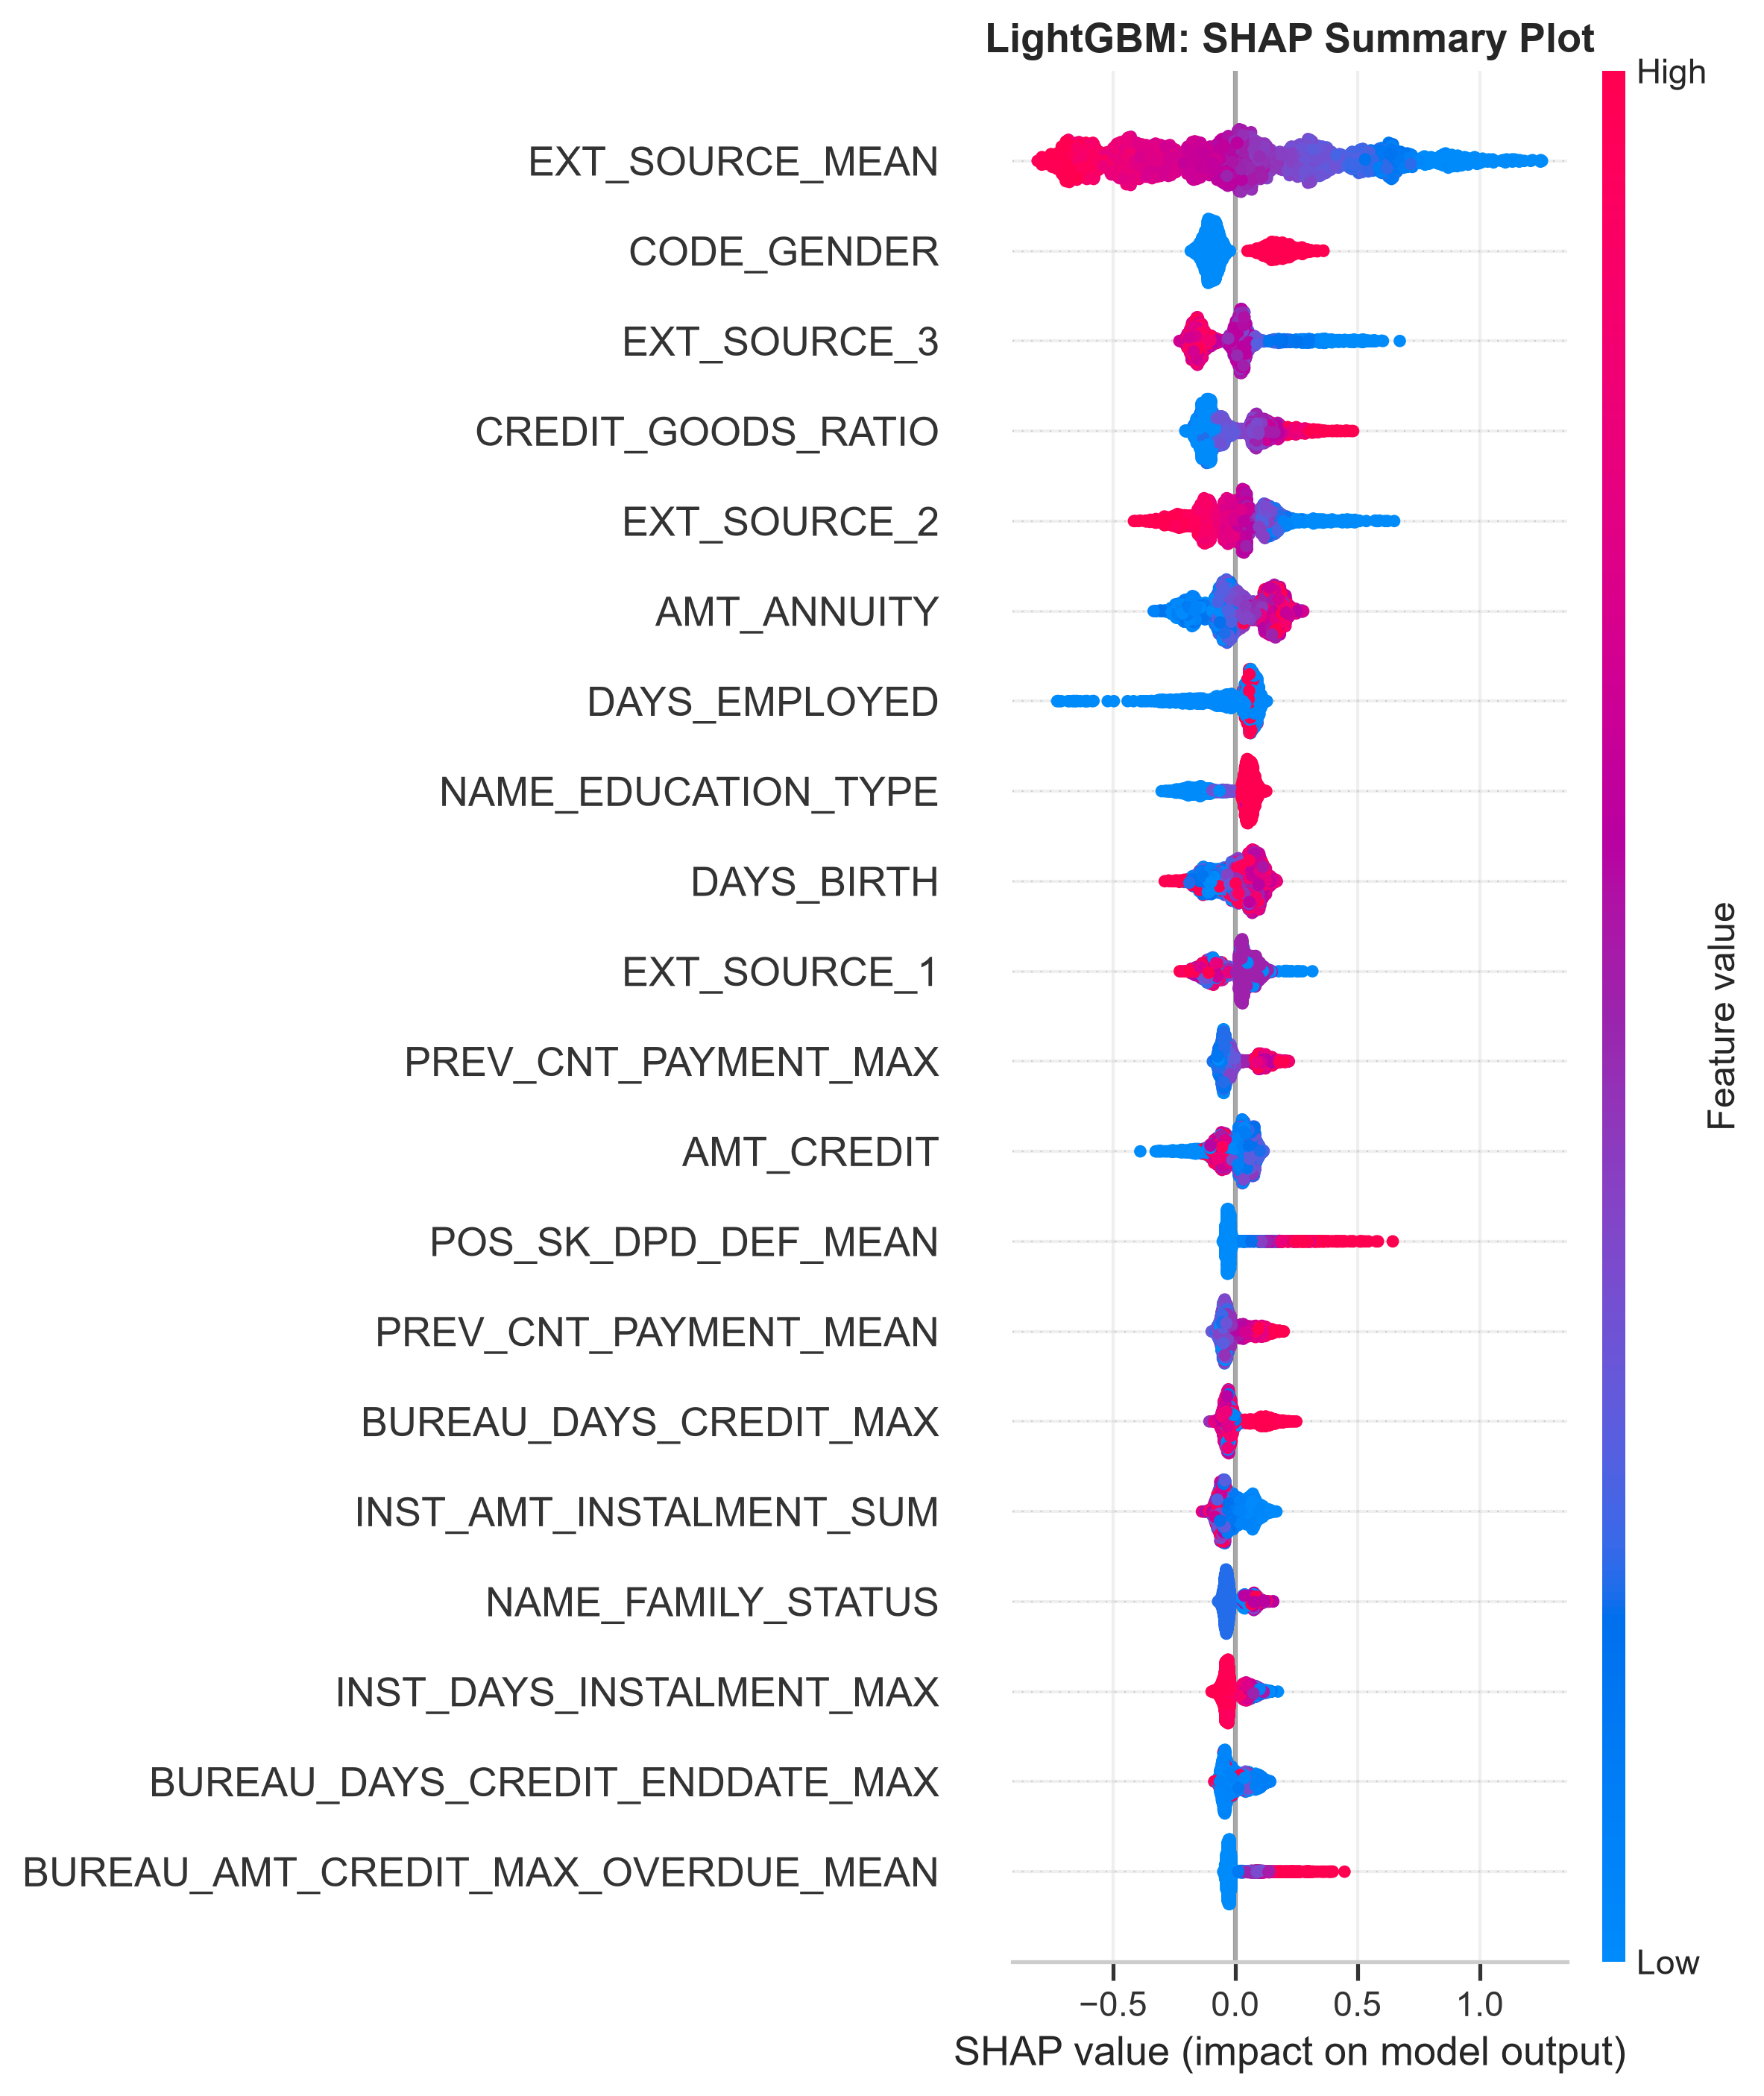

Figure saved to: ..\figures\12_lgbm_shap_feature_importance.png


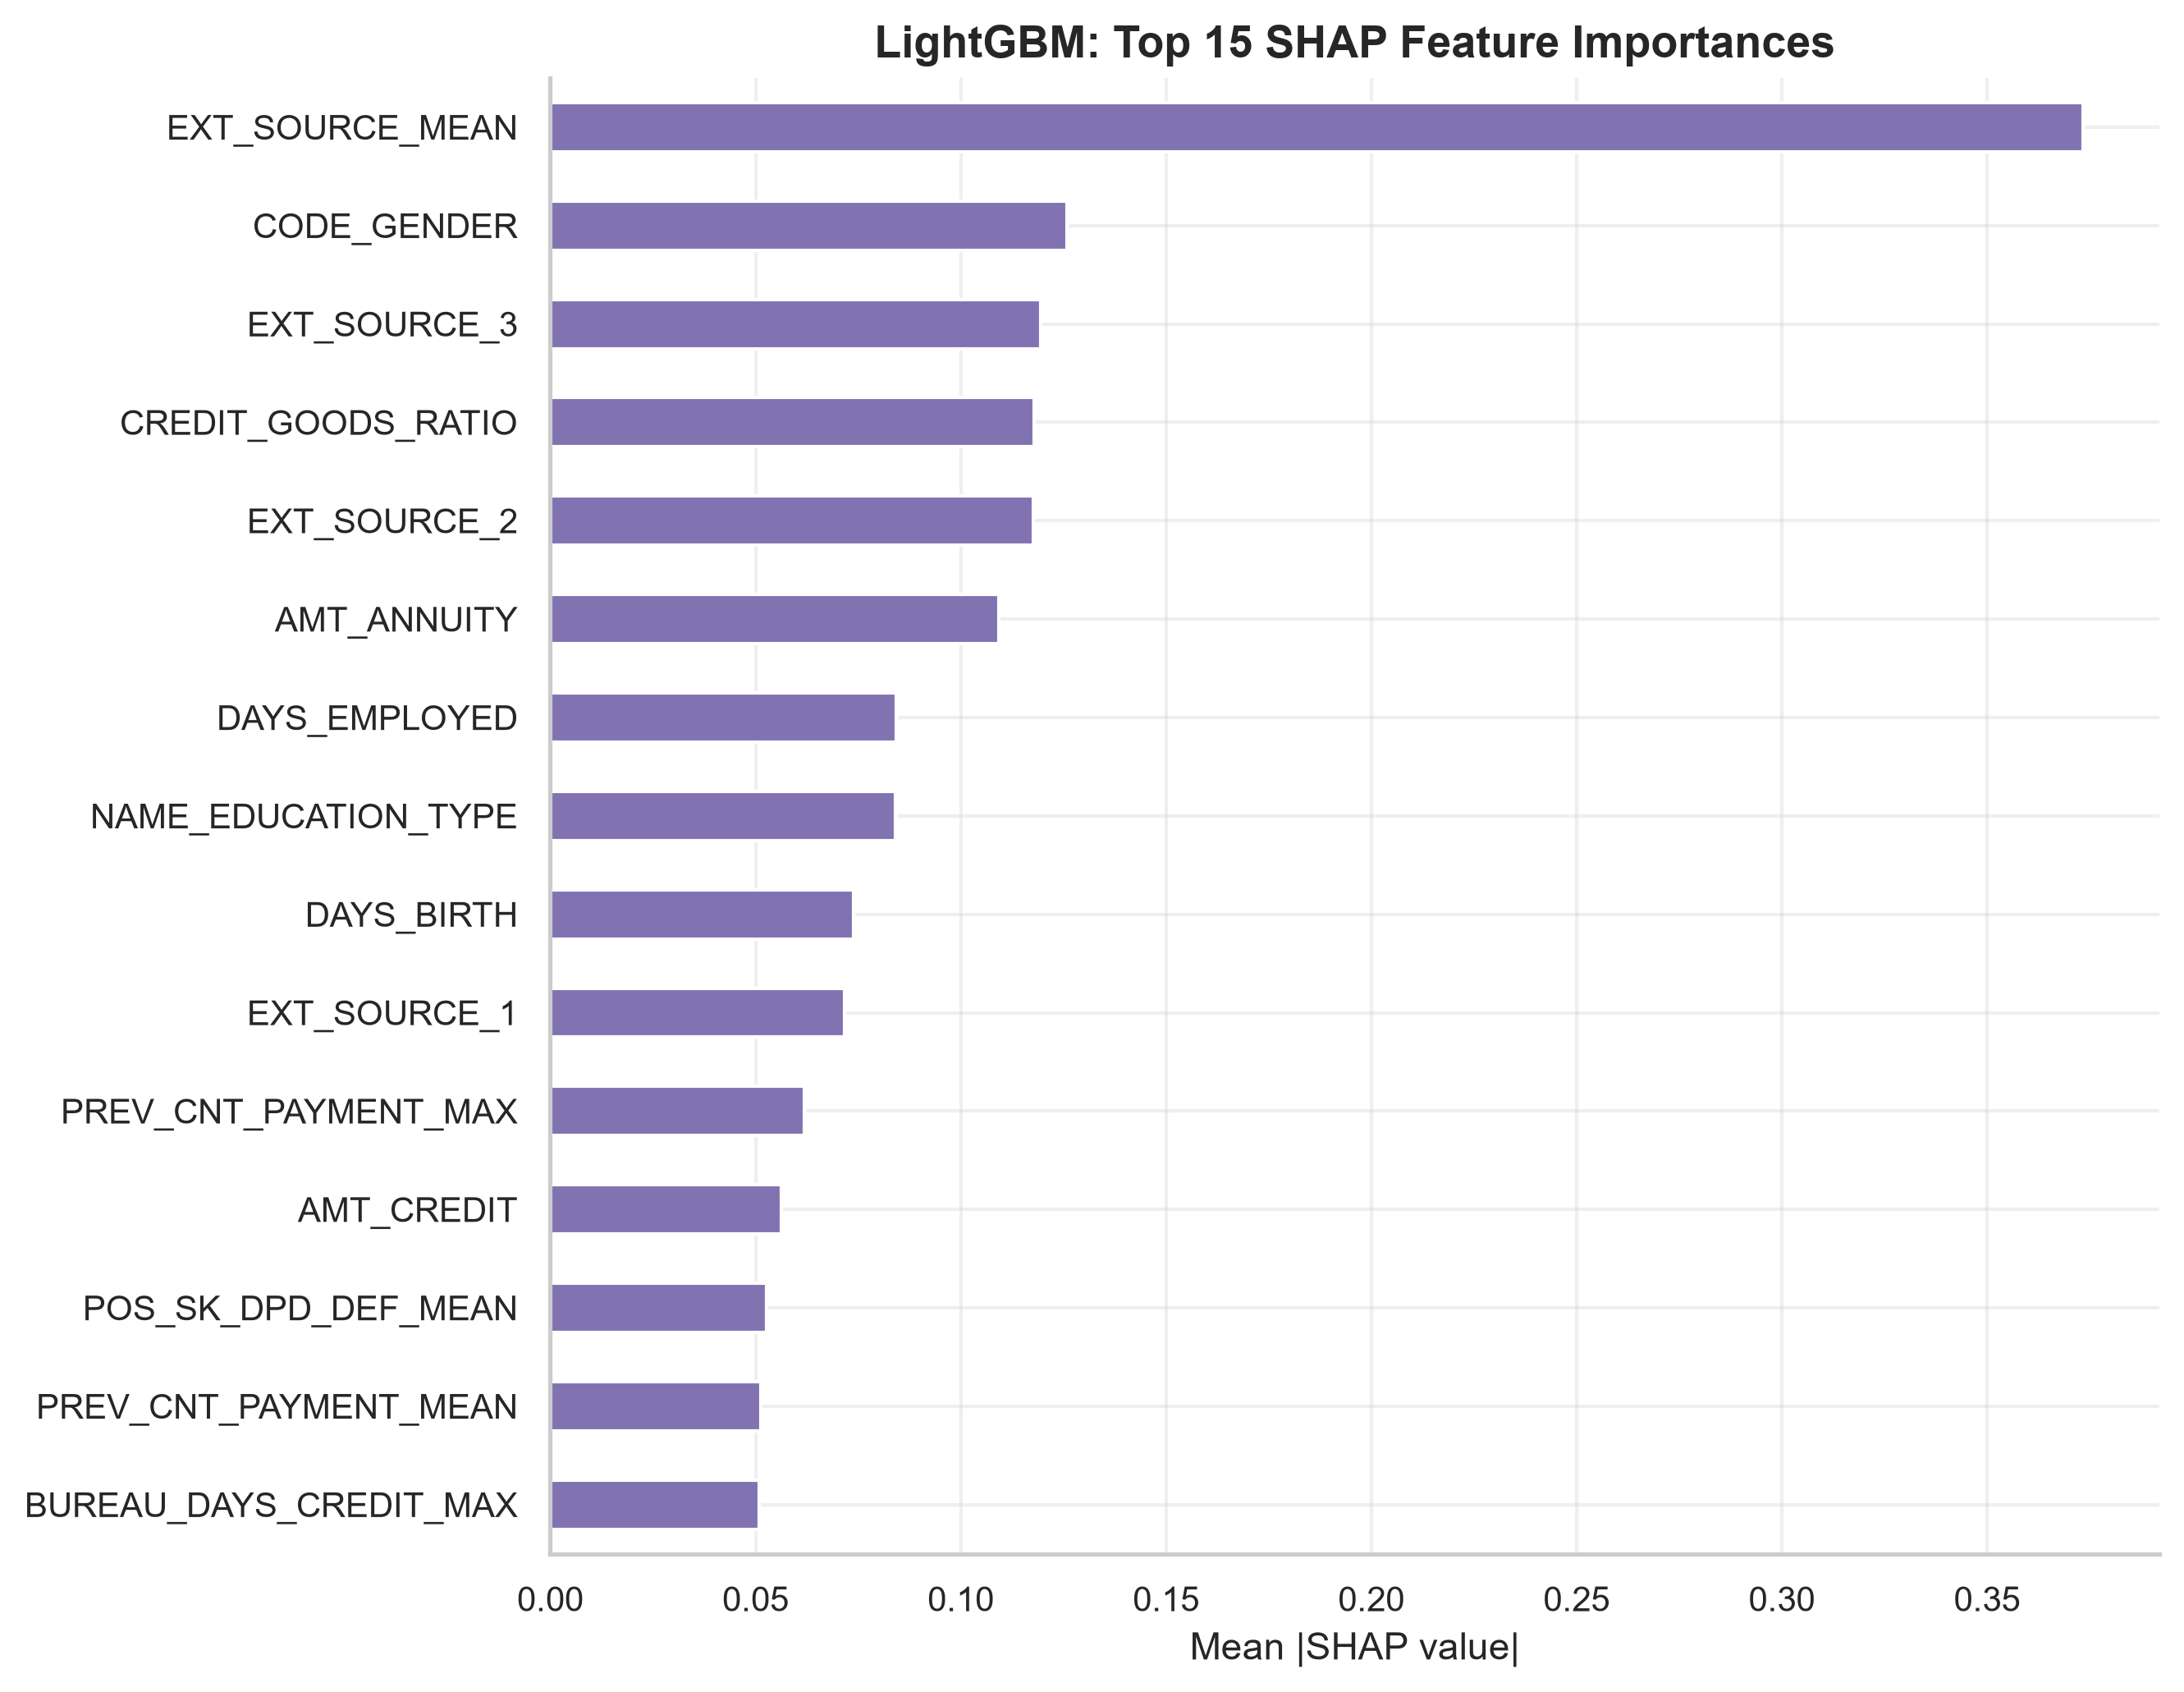

EXT_SOURCE_MEAN           0.373312
CODE_GENDER               0.125797
EXT_SOURCE_3              0.119427
CREDIT_GOODS_RATIO        0.117783
EXT_SOURCE_2              0.117594
AMT_ANNUITY               0.109307
DAYS_EMPLOYED             0.084368
NAME_EDUCATION_TYPE       0.083983
DAYS_BIRTH                0.073937
EXT_SOURCE_1              0.071700
PREV_CNT_PAYMENT_MAX      0.061874
AMT_CREDIT                0.056366
POS_SK_DPD_DEF_MEAN       0.052669
PREV_CNT_PAYMENT_MEAN     0.051312
BUREAU_DAYS_CREDIT_MAX    0.050864
dtype: float64

In [17]:
# ============================================================
# SHAP Explainability (Non-PCA Track, TreeExplainer): Summary & Importance
# ============================================================

import shap

DATA_DIR = Path("../data/processed")

X_train_full = pd.read_csv(DATA_DIR / "X_train_full.csv")
X_test_full = pd.read_csv(DATA_DIR / "X_test_full.csv")
y_train_full = pd.read_csv(DATA_DIR / "y_train_full.csv").squeeze()

lgbm_model_shap = LGBMClassifier(
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, **random_search.best_params_
)
lgbm_model_shap.fit(X_train_full, y_train_full)

explainer = shap.TreeExplainer(lgbm_model_shap)

shap_sample = X_test_full.sample(3000, random_state=RANDOM_STATE)
shap_values_raw = explainer.shap_values(shap_sample)

if isinstance(shap_values_raw, list):
    shap_values_default = shap_values_raw[1]
elif np.ndim(shap_values_raw) == 3:
    shap_values_default = shap_values_raw[:, :, 1]
else:
    shap_values_default = shap_values_raw

shap.summary_plot(shap_values_default, shap_sample, show=False)
fig = plt.gcf()
plt.title("LightGBM: SHAP Summary Plot")
plt.tight_layout()
pu.save_fig(fig, "12_lgbm_shap_summary")
plt.show()

mean_abs_shap = pd.Series(
    np.abs(shap_values_default).mean(axis=0), index=X_test_full.columns
).sort_values(ascending=False)

top_features = mean_abs_shap.head(15)

fig, ax = plt.subplots(figsize=(9, 7))
top_features.sort_values().plot(kind="barh", ax=ax, color="#8172B2")
ax.set_xlabel("Mean |SHAP value|")
ax.set_title("LightGBM: Top 15 SHAP Feature Importances")
plt.tight_layout()
pu.save_fig(fig, "12_lgbm_shap_feature_importance")
plt.show()

top_features.to_frame("Mean |SHAP value|").to_csv(Path("../results") / "12_lgbm_shap_top_features.csv")
top_features

Figure saved to: ..\figures\12_lgbm_shap_dependence.png


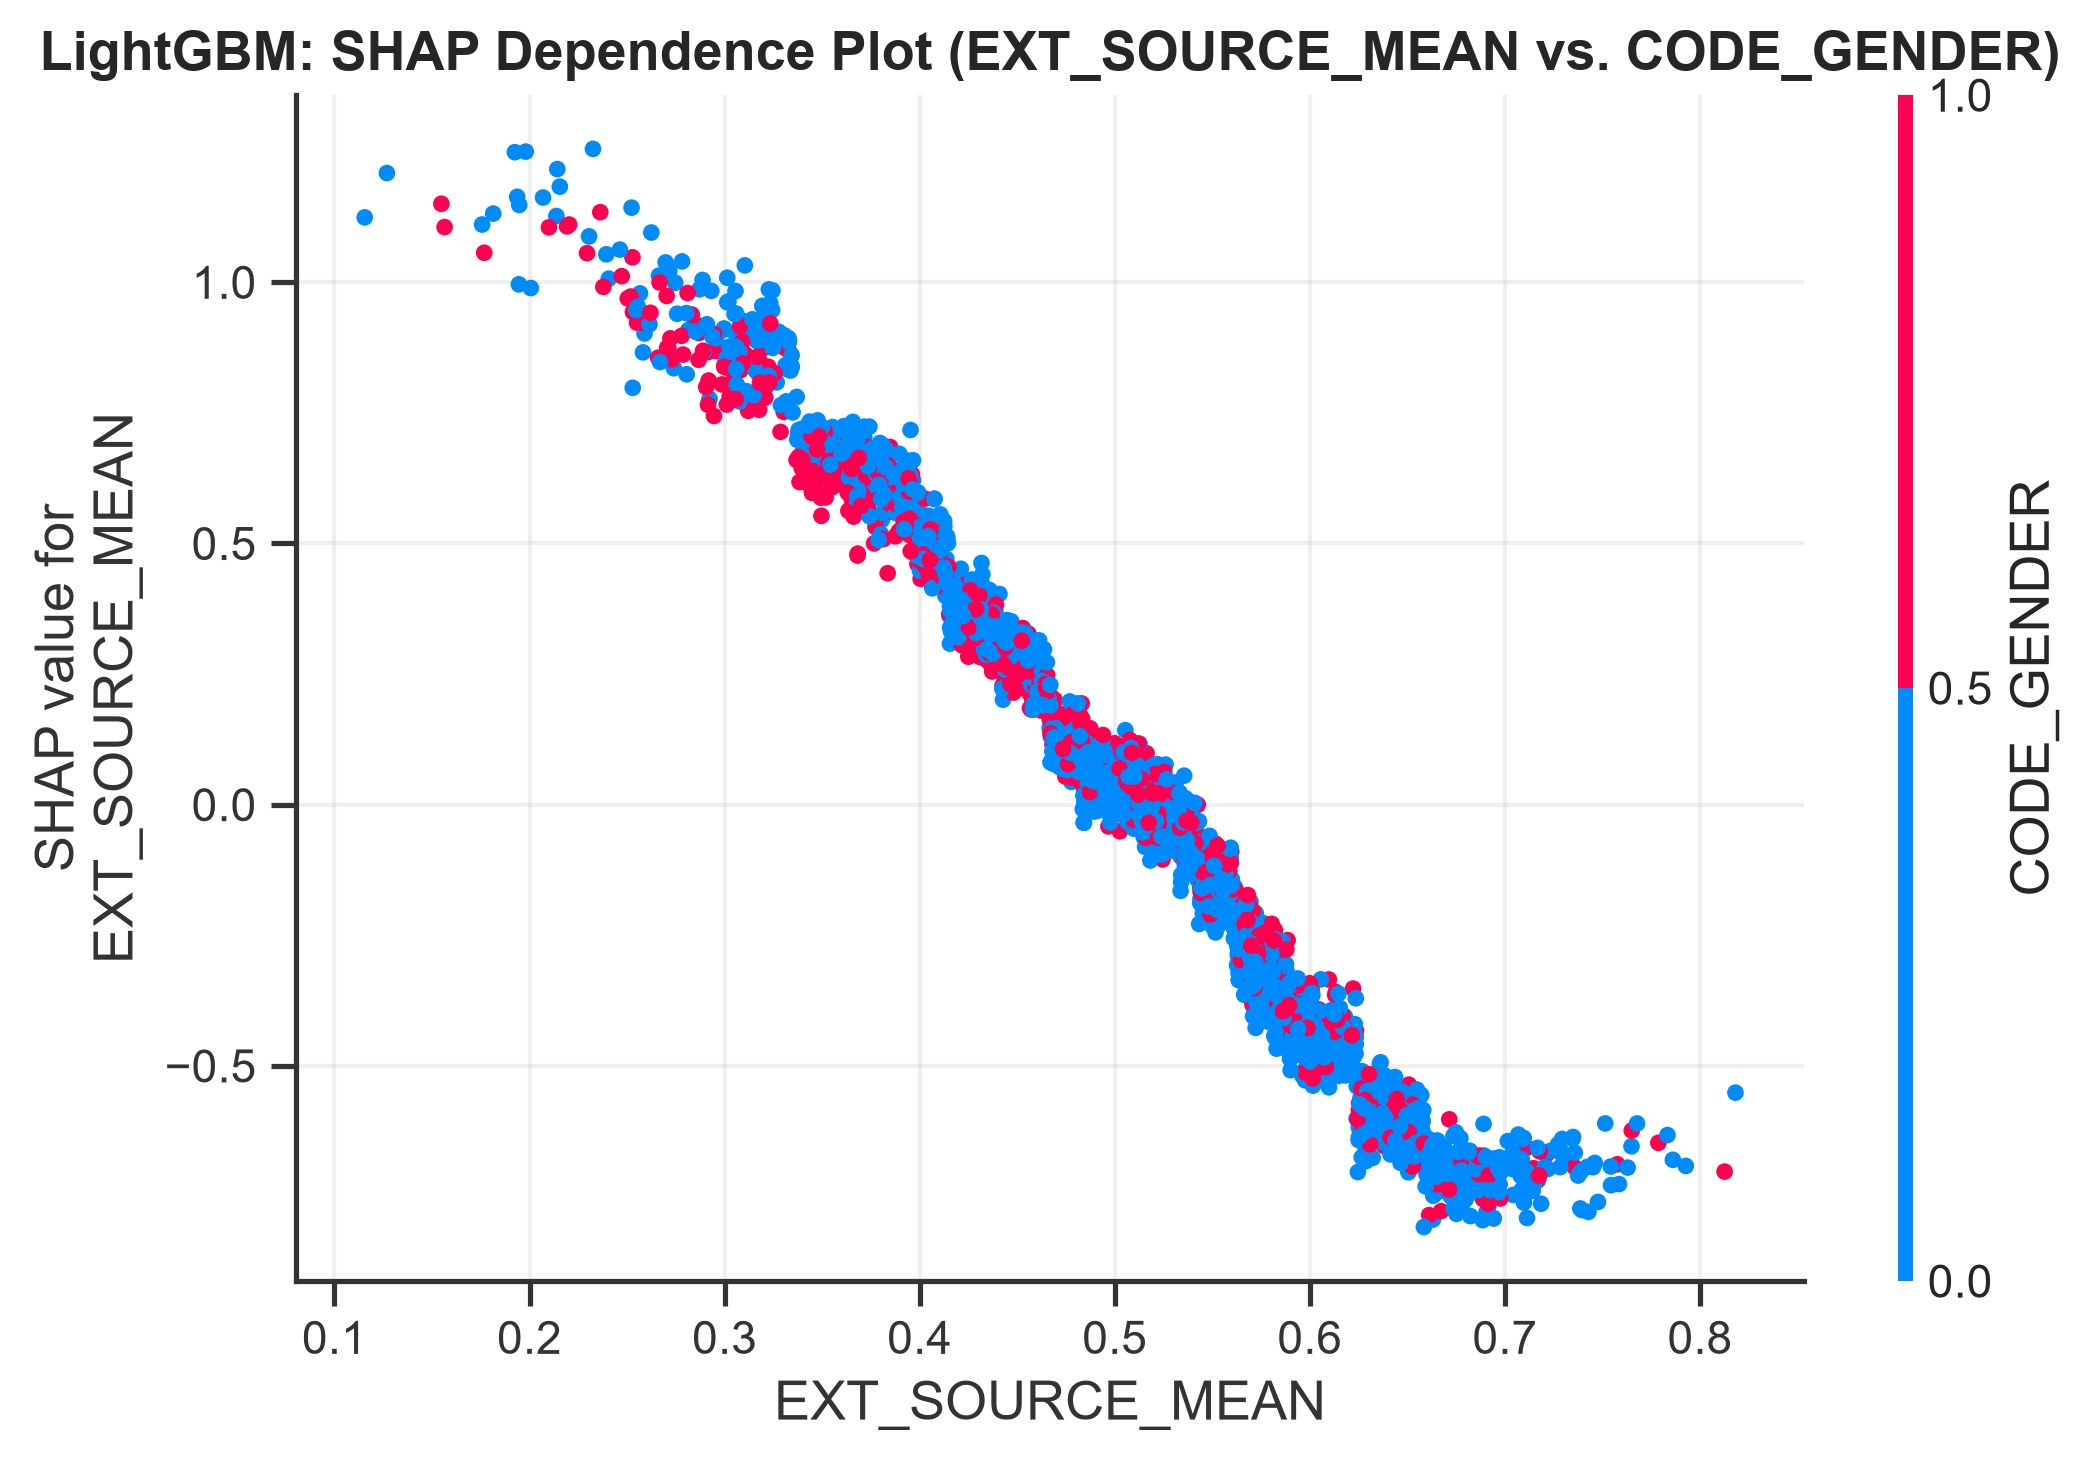

Low-risk applicant  - predicted default probability: 0.0307
High-risk applicant - predicted default probability: 0.9033


Figure saved to: ..\figures\12_lgbm_shap_local_low_risk.png


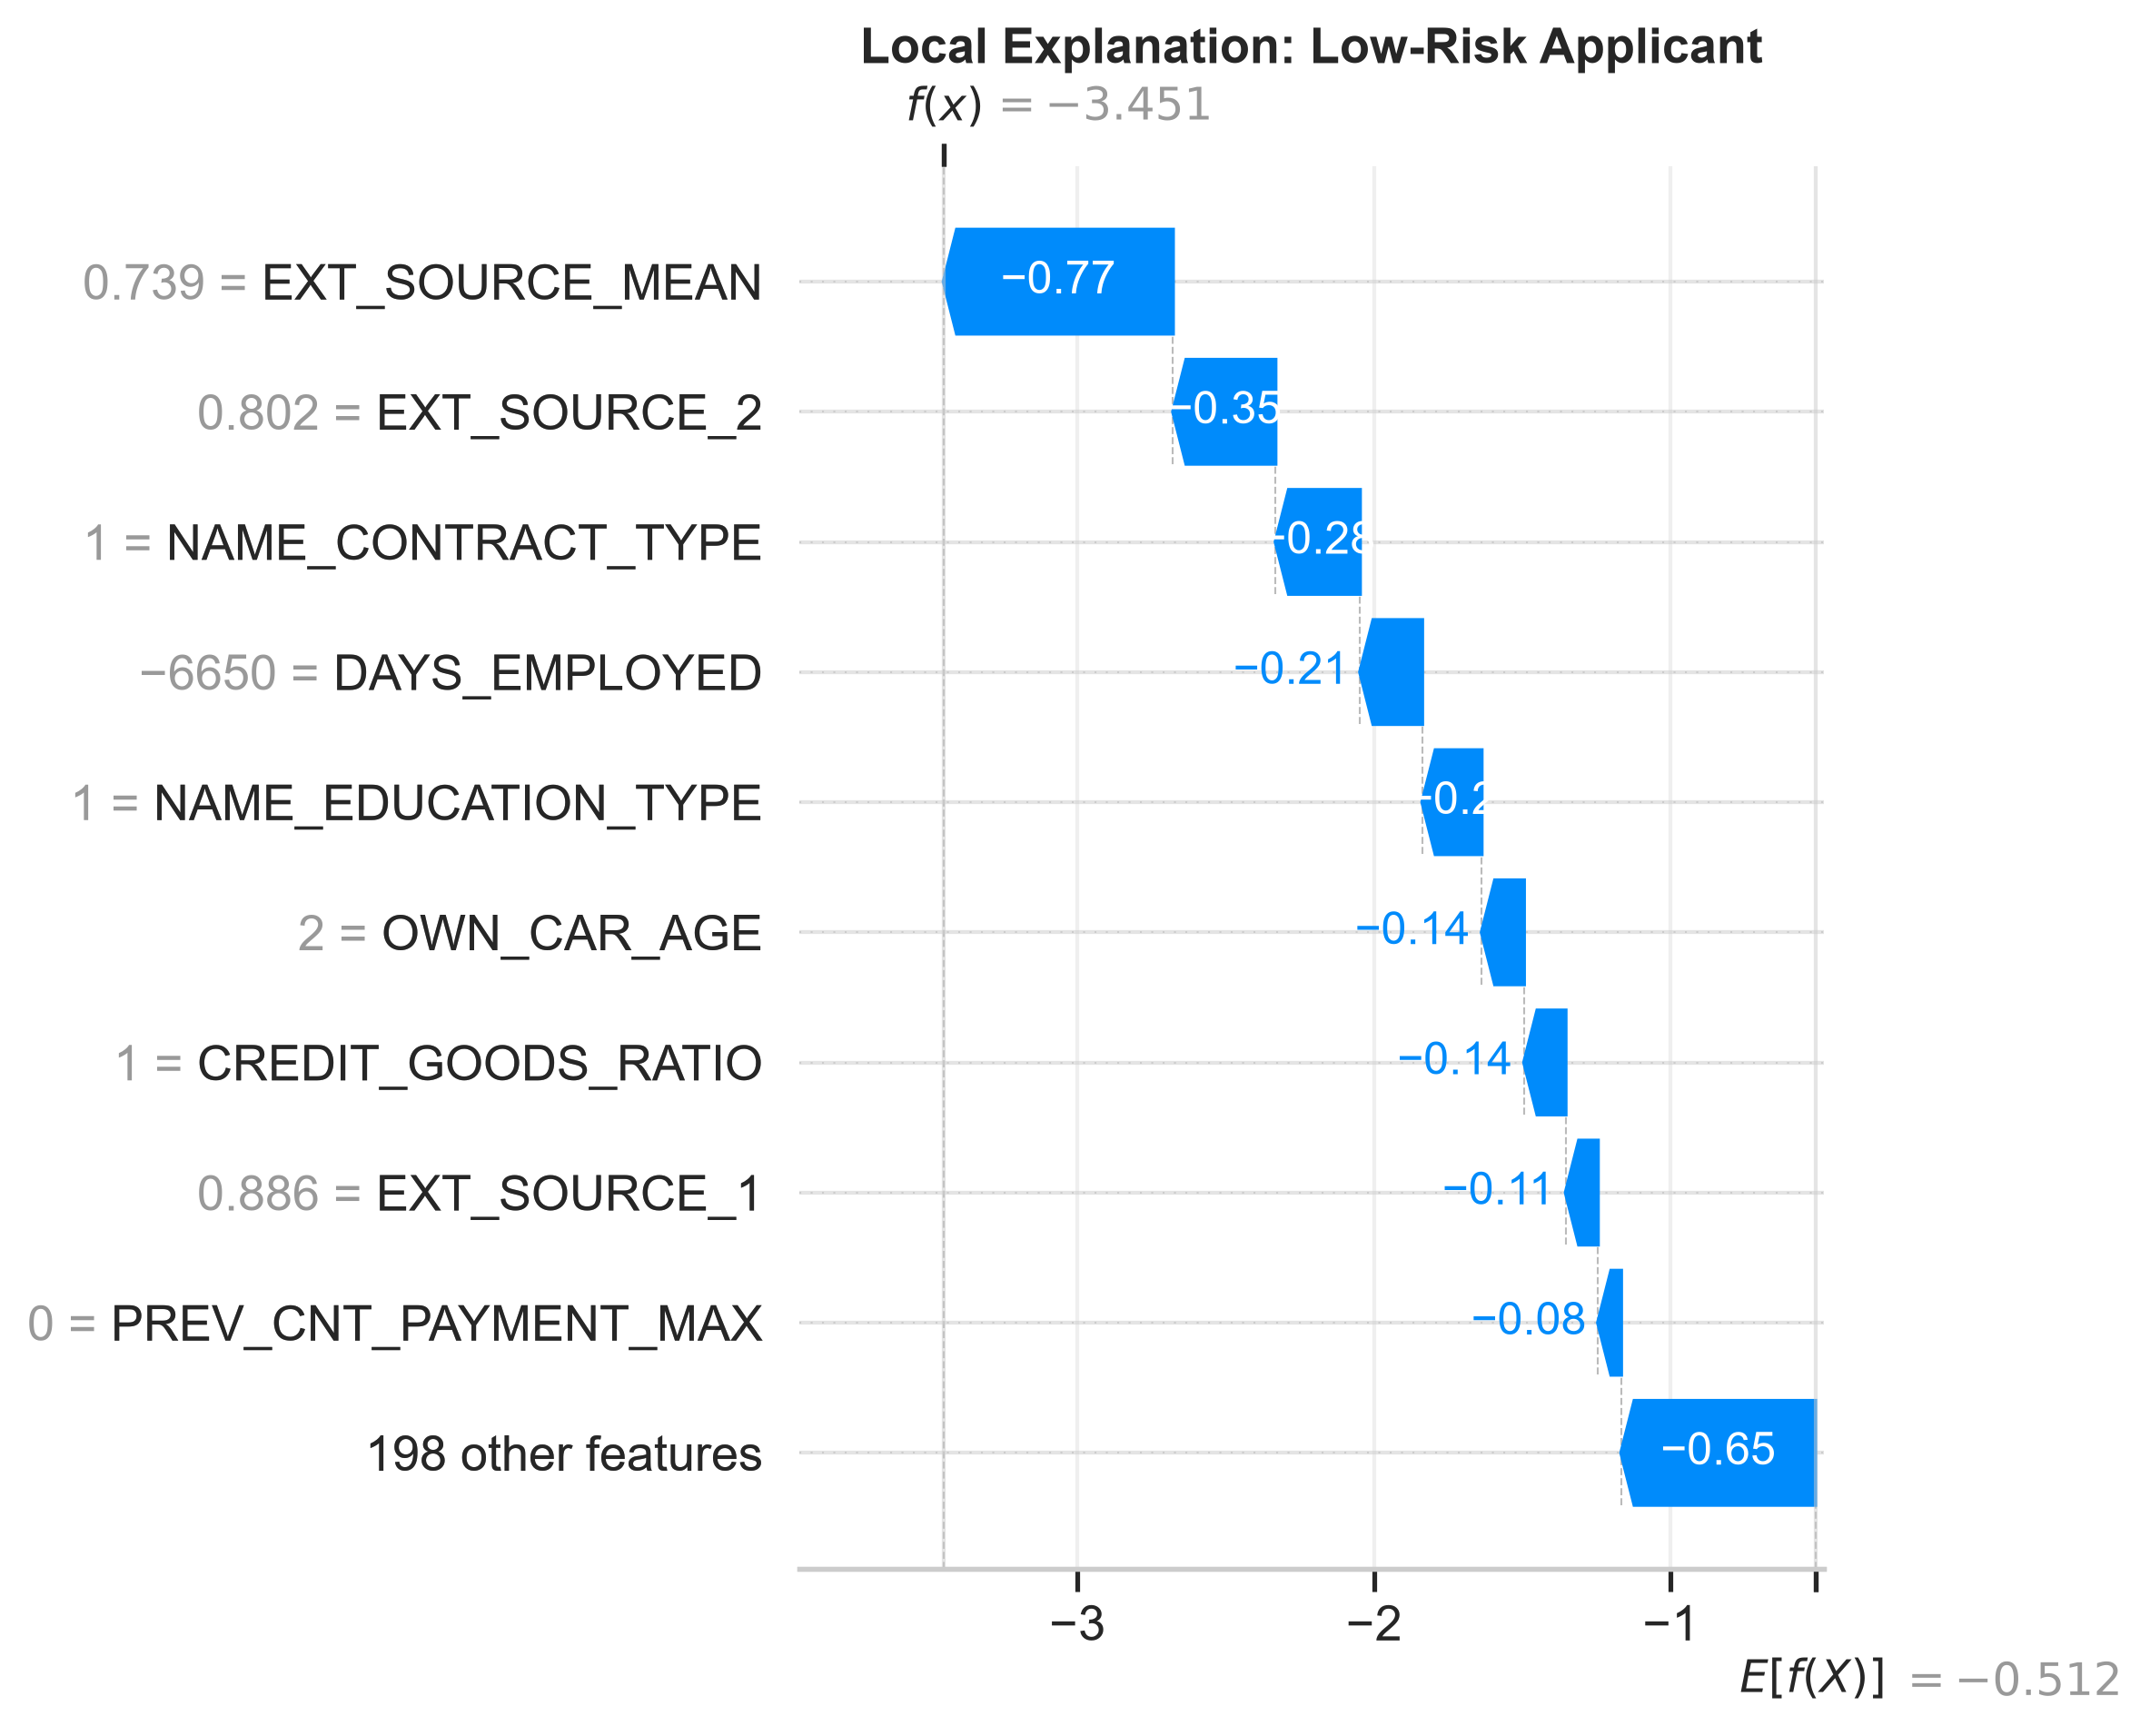

Figure saved to: ..\figures\12_lgbm_shap_local_high_risk.png


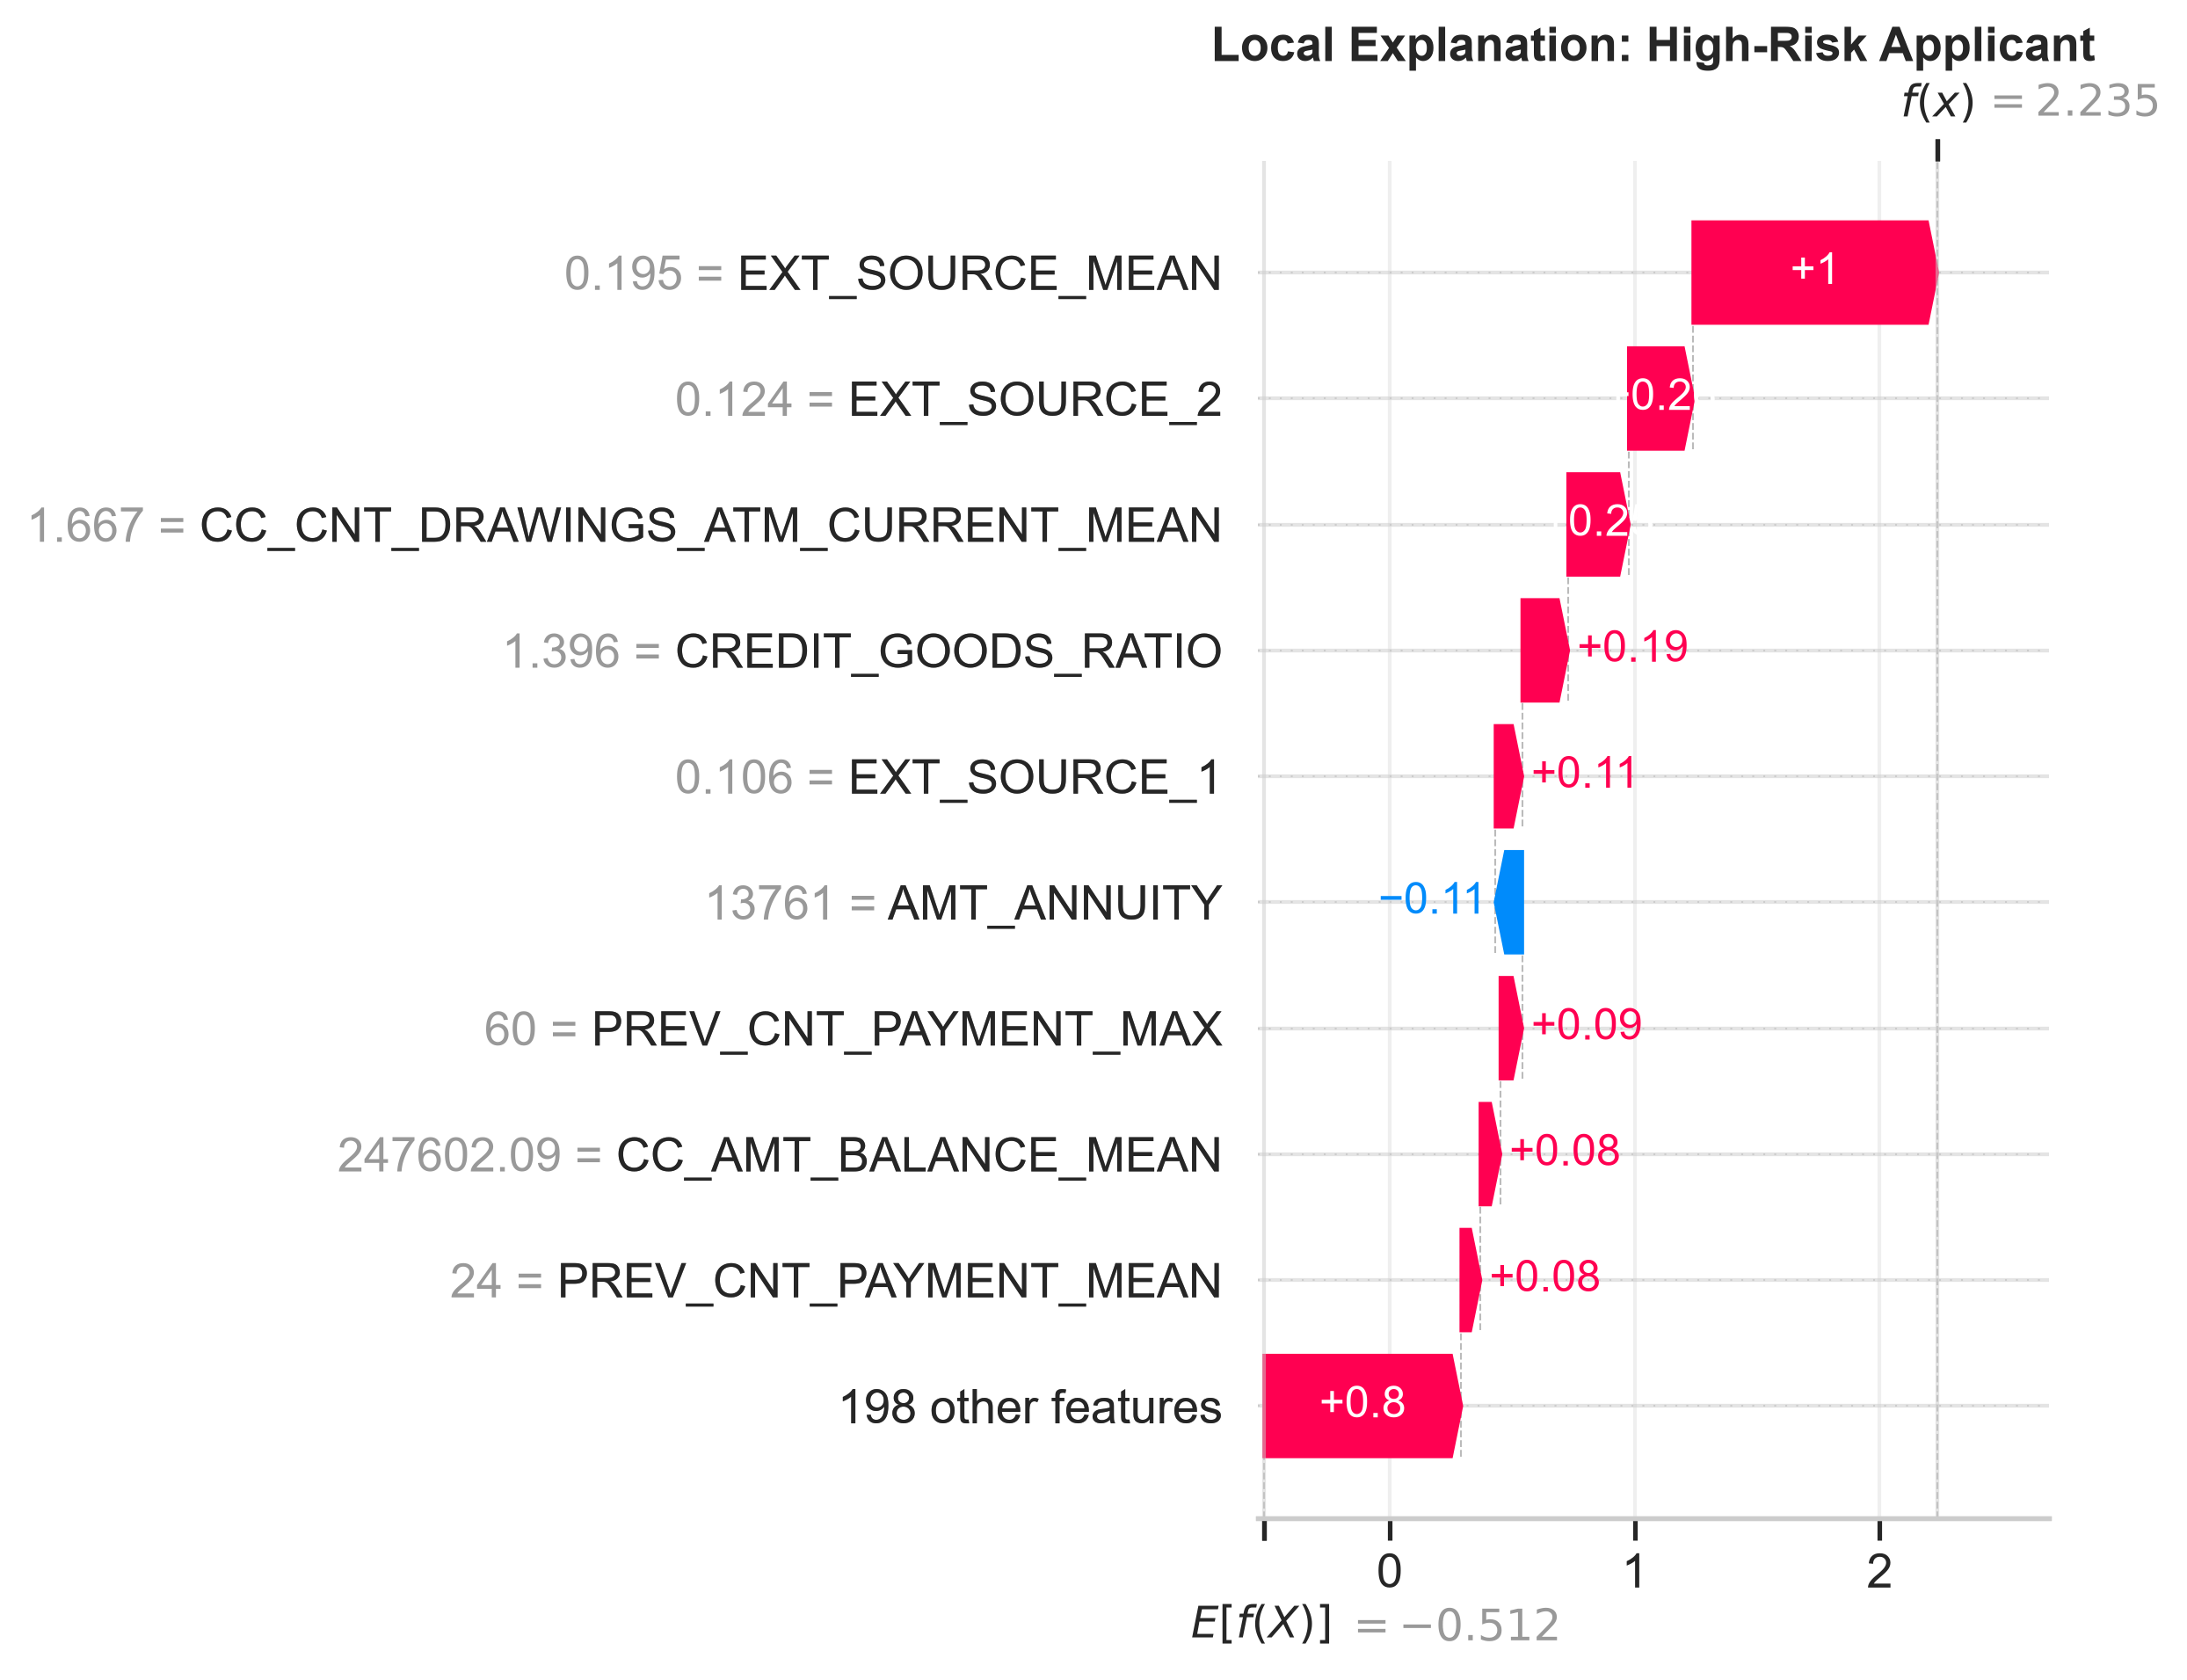

In [18]:
# ============================================================
# SHAP Dependence Plot & Local Explanations
# ============================================================

top_feature_name = mean_abs_shap.index[0]
second_feature_name = mean_abs_shap.index[1]

shap.dependence_plot(
    top_feature_name, shap_values_default, shap_sample,
    interaction_index=second_feature_name, show=False
)
fig = plt.gcf()
plt.title(f"LightGBM: SHAP Dependence Plot ({top_feature_name} vs. {second_feature_name})")
plt.tight_layout()
pu.save_fig(fig, "12_lgbm_shap_dependence")
plt.show()

predicted_prob_shap_sample = lgbm_model_shap.predict_proba(shap_sample)[:, 1]
low_risk_idx = int(np.argmin(predicted_prob_shap_sample))
high_risk_idx = int(np.argmax(predicted_prob_shap_sample))

print(f"Low-risk applicant  - predicted default probability: {predicted_prob_shap_sample[low_risk_idx]:.4f}")
print(f"High-risk applicant - predicted default probability: {predicted_prob_shap_sample[high_risk_idx]:.4f}")

explanation_full = explainer(shap_sample, check_additivity=False)
explanation = explanation_full[..., 1] if explanation_full.values.ndim == 3 else explanation_full

fig = plt.figure(figsize=(9, 6))
shap.plots.waterfall(explanation[low_risk_idx], show=False)
plt.title("Local Explanation: Low-Risk Applicant")
plt.tight_layout()
pu.save_fig(fig, "12_lgbm_shap_local_low_risk")
plt.show()

fig = plt.figure(figsize=(9, 6))
shap.plots.waterfall(explanation[high_risk_idx], show=False)
plt.title("Local Explanation: High-Risk Applicant")
plt.tight_layout()
pu.save_fig(fig, "12_lgbm_shap_local_high_risk")
plt.show()

Figure saved to: ..\figures\12_lgbm_shap_decision_plot.png


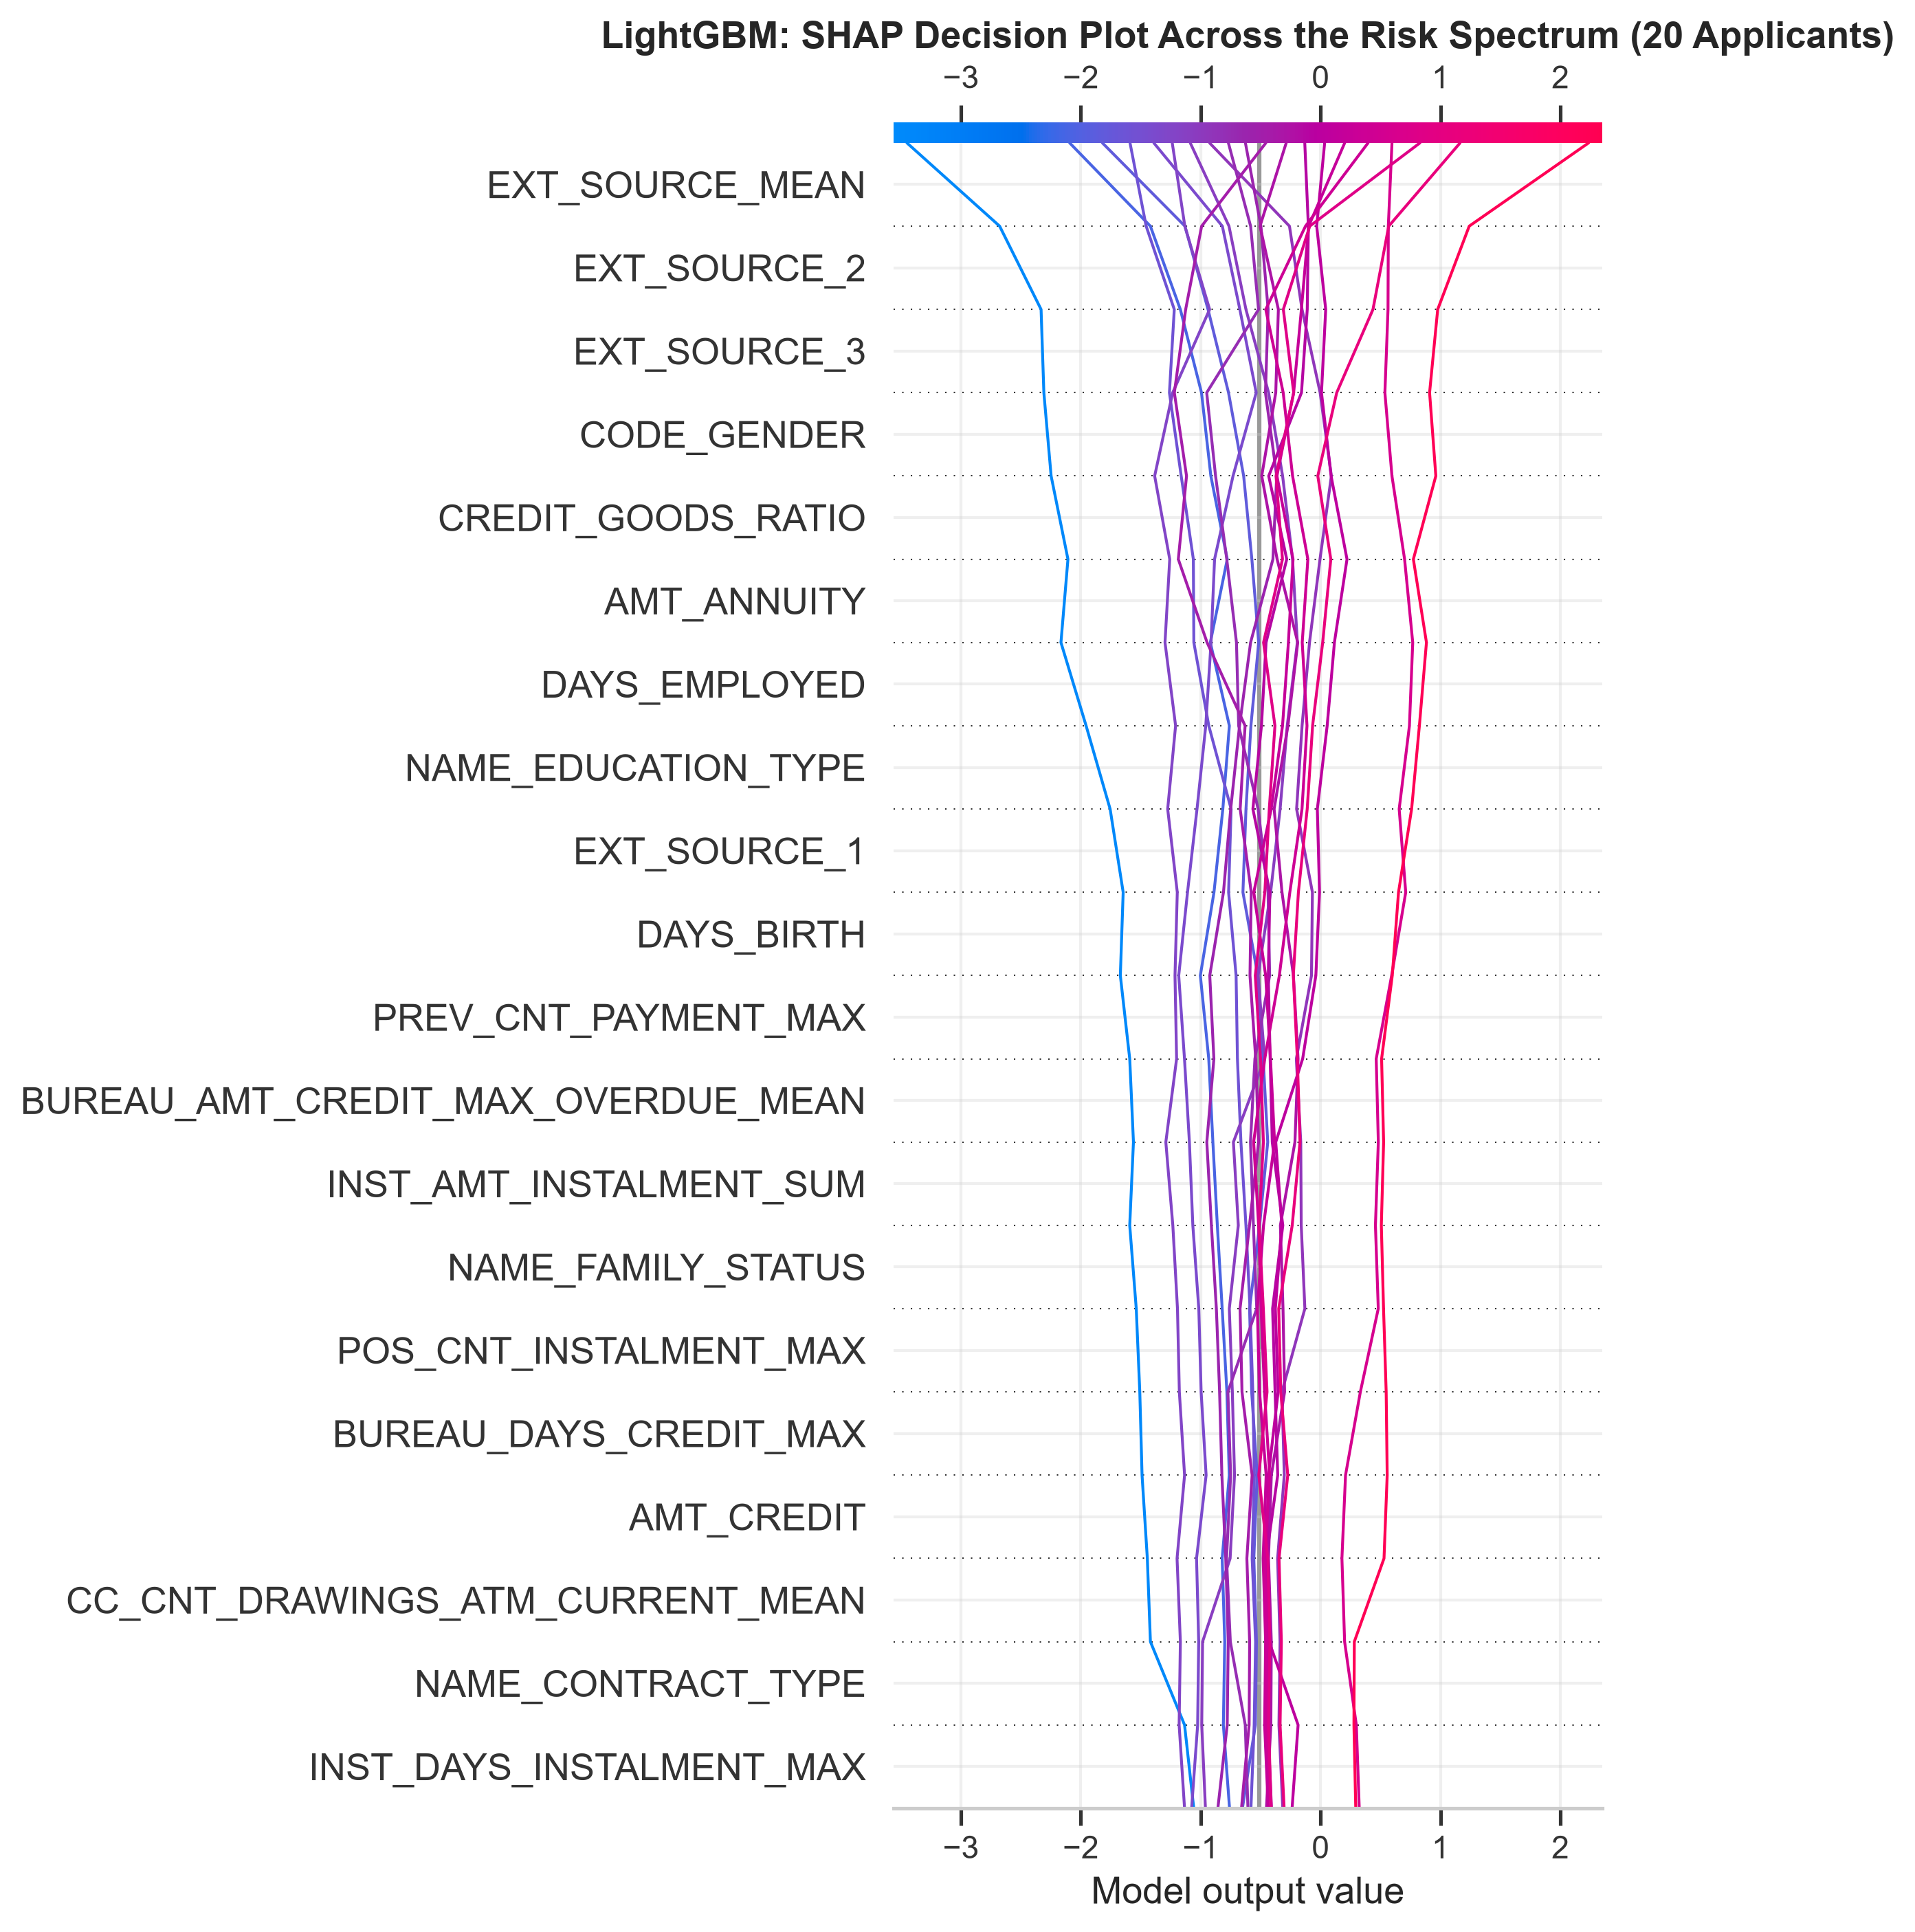

In [19]:
# ============================================================
# Flagship Analysis: Multi-Applicant SHAP Decision Plot
# ============================================================

# Select 20 applicants spanning the full predicted-risk spectrum (evenly spaced by rank)
order_by_risk = np.argsort(predicted_prob_shap_sample)
spread_idx = order_by_risk[np.linspace(0, len(order_by_risk) - 1, 20).astype(int)]

fig = plt.figure(figsize=(10, 8))
shap.decision_plot(
    explainer.expected_value if not isinstance(explainer.expected_value, (list, np.ndarray))
    else np.ravel(explainer.expected_value)[-1],
    shap_values_default[spread_idx],
    shap_sample.iloc[spread_idx],
    feature_order="importance",
    show=False,
)
plt.title("LightGBM: SHAP Decision Plot Across the Risk Spectrum (20 Applicants)")
plt.tight_layout()
pu.save_fig(fig, "12_lgbm_shap_decision_plot")
plt.show()

### Business Interpretation: SHAP Explainability (Flagship Analysis)

The dependence plot's secondary coloring feature (the second-most-important variable)
reveals whether the top feature's effect on risk is conditional on another attribute —
for example, whether a high `CREDIT_INCOME_RATIO` is only dangerous when
`EXT_SOURCE_MEAN` is also low, versus being uniformly risky regardless of external
credit history. Such interaction effects are invisible to a linear model like Logistic
Regression (Notebook 06) and are one of the concrete, evidence-backed reasons a paper
can give for why a boosted-tree model outperforms a linear scorecard on this dataset.

The multi-applicant decision plot is the single most useful figure in the project for a
non-technical audience (a lending committee, a regulator, a journal reviewer): each
line traces one applicant's predicted risk as it accumulates feature-by-feature from
the population base rate, and the fan-out pattern across 20 applicants spanning the
full risk spectrum visually demonstrates that the model produces a **smooth, graduated
risk continuum** rather than a small number of discrete risk clusters — direct visual
support for the legitimacy of the five-tier risk-band system (`Excellent` through
`High Risk`) used in Notebook 13's credit-scoring formula. Applicants whose lines
diverge sharply from the pack at a single feature are natural candidates for manual
underwriting review rather than fully automated decisioning, which is a concrete,
implementable recommendation this analysis can hand directly to a lending
operations team.